# 📊 Studi Kasus PT Maju Bersama
### *Make Sense of Data with Analysis and AI* — praktik Python di Google Colab

Notebook ini adalah pasangan praktik dari **Kuliah Praktisi Informatika UNIB** (narasumber: Dr. Andria Arisal, BRIN). Kita mengerjakan ulang studi kasus distributor **PT Maju Bersama** dari awal sampai akhir: **omzet naik, tetapi laba bersih turun 14%, piutang tak tertagih naik ±300%, dan arus kas operasional defisit.** Mengapa bisa begitu, dan apa yang harus dilakukan?

| Materi kuliah | Bagian di notebook |
|---|---|
| Data → Informasi → Wawasan → Keputusan | Seluruh notebook (alurnya mengikuti rantai ini) |
| CRISP-DM (6 tahap) | Bagian 1–10 (tiap bagian diberi label tahap CRISP-DM) |
| *Garbage In, Garbage Out* | Bagian 2–3 (data kotor sengaja disuntikkan, lalu dibersihkan) |
| 4 tingkat analitik | Bagian 4 (deskriptif), 5 (diagnostik), 6 (prediktif), 7 (preskriptif) |
| Market Basket Analysis (Apriori/FP-Growth; support, confidence, lift) | Bagian 8 |
| Data masking & *human-in-the-loop* | Bagian 9 |
| Evaluation & Deployment | Bagian 6.1 (evaluasi) dan 10 (deployment) |
| Alternatif KNIME (alur visual) | Bagian 11 (padanan node KNIME ↔ kode Python) |

**Cara pakai:** klik **Runtime → Run all** (Ctrl+F9). Seluruh notebook berjalan sekitar 1–2 menit.

> ⚠️ **Catatan penting:** semua data di sini **sintetis** (dibangkitkan oleh kode), bukan data asli perusahaan. Parameter simulasi dikalibrasi agar angka makro mengikuti skenario kuliah (laba bersih −14%, piutang macet ±4×, arus kas operasional 2025 negatif). Pola di tingkat transaksi (siapa menunggak, produk apa dibeli bersamaan) adalah bagian yang harus **kamu temukan** lewat analisis.

## 0. Persiapan

In [1]:
import sys, subprocess, importlib.util, warnings, hashlib, re, joblib
warnings.filterwarnings("ignore")

# mlxtend (Apriori / FP-Growth) biasanya sudah ada di Colab; kalau belum, dipasang otomatis
if importlib.util.find_spec("mlxtend") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlxtend"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.options.display.float_format = "{:,.2f}".format

RANDOM_STATE = 42
WARNA = {"biru": "#264653", "hijau": "#2a9d8f", "kuning": "#e9c46a", "oranye": "#f4a261", "merah": "#e76f51"}

def rp_m(x):   return f"Rp {x/1e9:,.2f} M"      # miliar rupiah
def rp_jt(x):  return f"Rp {x/1e6:,.1f} jt"     # juta rupiah
def rp_auto(x):                                  # miliar bila besar, juta bila kecil; tanda minus rapi
    tanda = "-" if x < 0 else ""
    x = abs(x)
    return f"{tanda}Rp {x/1e9:,.2f} M" if x >= 1e9 else f"{tanda}Rp {x/1e6:,.0f} jt"
def pct(x, d=1): return f"{x*100:+.{d}f}%"       # persen dengan tanda
print("Siap. Versi pandas:", pd.__version__)

Siap. Versi pandas: 3.0.5


---
## 1. Business Understanding  *(CRISP-DM tahap 1)*

**Situasi.** PT Maju Bersama adalah distributor barang kebutuhan sehari-hari (sembako, minuman, perawatan, rumah tangga) yang melayani warung, toko grosir, minimarket, kafe, dan kantin di Bengkulu dan sekitarnya. Sebagian besar penjualan dilakukan **secara kredit** (jatuh tempo 14–45 hari).

Pada **April 2025** manajemen mengambil kebijakan agresif untuk mengejar omzet: **diskon lebih besar**, **batas kredit pelanggan dilonggarkan (2×)**, dan **tenor kredit diperpanjang**. Penagihan tidak diperketat.

**Gejala di laporan keuangan:** omzet naik, tetapi laba bersih turun, piutang macet melonjak, dan kas operasional defisit.

| Pertanyaan bisnis | Tingkat analitik | Bagian |
|---|---|---|
| *Apa yang terjadi* pada omzet, laba, piutang, dan kas? | Deskriptif | 4 |
| *Mengapa* laba turun padahal omzet naik? | Diagnostik | 5 |
| *Faktur/pelanggan mana* yang kemungkinan besar macet? | Prediktif | 6 |
| *Apa yang sebaiknya dilakukan* manajemen? | Preskriptif | 7 |
| Produk apa yang layak dibundel untuk *cross-selling*? | Association rule mining | 8 |

**Kriteria sukses:** (1) penyebab turunnya laba dapat dijelaskan secara kuantitatif; (2) ada model skor risiko yang menangkap proporsi besar faktur macet hanya dengan menandai sebagian kecil faktur; (3) ada rekomendasi kebijakan yang dapat dihitung manfaatnya; (4) data sensitif aman dan hasil AI tetap diverifikasi manusia.

---
## 2. Data Understanding  *(CRISP-DM tahap 2)*

Di dunia industri, data tidak datang rapi. Sel di bawah ini membangkitkan lima tabel seperti hasil ekspor sistem ERP/kasir, **lengkap dengan "kotoran"**: baris duplikat, nilai kosong, penulisan kota tidak konsisten, format telepon campur aduk, dan beberapa salah ketik jumlah barang. (Kode generatornya disembunyikan; klik *Show code* bila ingin melihatnya.)

| Tabel | Isi |
|---|---|
| `produk` | 24 produk: harga list dan HPP |
| `pelanggan_raw` | 320 pelanggan: kota, jenis usaha, rating kredit awal (A/B/C), telepon |
| `lines_raw` | detail baris penjualan per faktur: produk, jumlah, harga list, diskon |
| `faktur_raw` | tanggal, tenor, batas kredit, piutang berjalan, tanggal bayar (kosong = belum/tidak dibayar) |
| `beban_raw` | biaya operasional bulanan |

Faktur Nov–Des 2023 hanya dipakai sebagai **saldo piutang awal** untuk menghitung arus kas; analisis laba memakai **2024 vs 2025**. Data diambil (*snapshot*) pada **30 April 2026**.

In [2]:
#@title ⚙️ Generator data sintetis (jalankan saja, tidak perlu dibaca) { display-mode: "form" }
def buat_dataset(seed=2026, n_cust=320):
    rng = np.random.default_rng(seed)
    rng2 = np.random.default_rng(seed + 1)          # untuk "mengotori" data

    # ---------------- Produk ----------------
    daftar = [
        ("P01","Beras Premium 25kg","Sembako",310000), ("P02","Minyak Goreng 2L (karton)","Sembako",230000),
        ("P03","Gula Pasir 50kg","Sembako",640000),    ("P04","Tepung Terigu 25kg","Sembako",270000),
        ("P05","Telur Ayam (peti)","Sembako",420000),  ("P06","Mie Instan (dus)","Makanan",115000),
        ("P07","Kecap Manis (karton)","Makanan",160000),("P08","Saus Sambal (karton)","Makanan",150000),
        ("P09","Kopi Sachet (karton)","Minuman",95000), ("P10","Teh Celup (karton)","Minuman",85000),
        ("P11","Susu UHT (karton)","Minuman",245000),   ("P12","Biskuit (karton)","Makanan",130000),
        ("P13","Air Mineral (dus)","Minuman",48000),    ("P14","Minuman Soda (karton)","Minuman",125000),
        ("P15","Snack Kentang (karton)","Makanan",140000),("P16","Permen (karton)","Makanan",90000),
        ("P17","Sabun Mandi (karton)","Perawatan",210000),("P18","Shampoo Sachet (karton)","Perawatan",180000),
        ("P19","Pasta Gigi (karton)","Perawatan",260000),("P20","Deterjen Bubuk (karton)","Rumah Tangga",220000),
        ("P21","Pewangi Pakaian (karton)","Rumah Tangga",175000),("P22","Tisu (karton)","Rumah Tangga",110000),
        ("P23","Margarin (karton)","Sembako",195000),   ("P24","Susu Kental Manis (karton)","Minuman",280000)]
    produk = pd.DataFrame(daftar, columns=["product_id", "nama_produk", "kategori", "harga_list"])
    produk["hpp"] = (produk["harga_list"] * rng.uniform(0.86, 0.90, len(produk))).round(-2)
    pid_all = produk["product_id"].tolist()
    harga = dict(zip(produk.product_id, produk.harga_list))
    paket = [["P06","P05","P07"], ["P09","P03"], ["P10","P03"], ["P02","P01"], ["P17","P18","P19"],
             ["P20","P21"], ["P11","P12"], ["P04","P23","P05"], ["P13","P14","P15"], ["P09","P24"]]

    # ---------------- Pelanggan ----------------
    jenis = rng.choice(["Warung","Toko Grosir","Minimarket","Kafe/Restoran","Kantin Institusi"], n_cust, p=[.38,.24,.18,.12,.08])
    kota = rng.choice(["Bengkulu","Curup","Manna","Arga Makmur","Kepahiang","Mukomuko"], n_cust, p=[.4,.2,.12,.12,.1,.06])
    awalan = ["Toko","Warung","UD","CV","Kios","Minimarket","Kafe"]
    k1 = ["Sumber","Makmur","Jaya","Barokah","Sentosa","Mandiri","Abadi","Berkah","Harapan","Rezeki","Indah","Lestari","Maju","Bintang","Cahaya"]
    k2 = ["Rejeki","Sejahtera","Utama","Baru","Karya","Mulia","Sari","Putra","Bersama","Pratama"]
    nama = [f"{rng.choice(awalan)} {rng.choice(k1)} {rng.choice(k2)} {i+1:03d}" for i in range(n_cust)]
    risk = rng.beta(1.2, 4.5, n_cust)                       # risiko laten: TIDAK diketahui perusahaan
    skor_awal = risk + rng.normal(0, 0.12, n_cust)           # penilaian kredit awal (tidak sempurna)
    rating = np.where(skor_awal < 0.15, "A", np.where(skor_awal < 0.35, "B", "C"))
    ukuran = rng.lognormal(0, 0.5, n_cust)
    limit_dasar = np.where(rating == "A", 30e6, np.where(rating == "B", 18e6, 10e6)) * ukuran ** 0.6
    limit_dasar = (limit_dasar / 1e6).round(0) * 1e6
    bergabung = pd.Timestamp("2021-01-01") + pd.to_timedelta(rng.integers(0, 1000, n_cust), unit="D")
    telp = ["08" + "".join(map(str, rng.integers(0, 10, 10))) for _ in range(n_cust)]
    cid = np.array([f"C{i+1:04d}" for i in range(n_cust)])
    pelanggan = pd.DataFrame({"customer_id": cid, "nama_pelanggan": nama, "telepon": telp, "kota": kota,
                              "jenis_usaha": jenis, "rating_kredit": rating, "tanggal_bergabung": bergabung})

    # ---------------- Transaksi ----------------
    bulan = pd.date_range("2023-11-01", "2025-12-01", freq="MS")
    kebijakan = pd.Timestamp("2025-04-01")
    buka = [[] for _ in range(n_cust)]
    baris, fk = [], []
    no = 0; ln = 0
    for mi, b in enumerate(bulan):
        post = b >= kebijakan
        n_inv = int(rng.normal(330 * (1 + 0.007 * mi) * (1.25 if post else 1.0), 8))
        w = ukuran * np.where(risk > 0.35, 1.29 if post else 0.5, 1.0)
        cs = rng.choice(n_cust, n_inv, p=w / w.sum())
        tgl = np.sort(rng.integers(0, b.days_in_month, n_inv))
        for k in range(n_inv):
            c = cs[k]; t0 = b + pd.Timedelta(days=int(tgl[k])); no += 1
            inv_id = f"INV{no:06d}"
            if rng.random() < 0.5:                       # separuh transaksi mengikuti pola "paket" kebiasaan beli
                items = list(paket[rng.integers(len(paket))])
                items += [pid_all[rng.integers(len(pid_all))] for _ in range(rng.integers(0, 3))]
            else:
                items = list(rng.choice(pid_all, rng.integers(1, 6), replace=False))
            items = list(dict.fromkeys(items))
            if post:
                if risk[c] > 0.35: disc = rng.choice([0.03, 0.05, 0.07, 0.09], p=[.2, .3, .3, .2])
                else:              disc = rng.choice([0.0, 0.02, 0.03, 0.04, 0.05], p=[.2, .2, .25, .2, .15])
            else:
                disc = rng.choice([0.0, 0.02, 0.03, 0.05], p=[.3, .25, .3, .15])
            disc = float(disc)
            term = int(rng.choice([14, 30, 45], p=[.05, .40, .55] if post else [.25, .60, .15]))
            jumlah = 0.0; hpp_tot = 0.0
            for pid in items:
                qty = int(rng.integers(2, 11) * (2 if ukuran[c] > 1.5 else 1))
                ln += 1
                baris.append((f"L{ln:07d}", inv_id, t0, cid[c], pid, qty, harga[pid], disc))
                jumlah += qty * harga[pid] * (1 - disc)
                hpp_tot += qty * produk.hpp.iat[pid_all.index(pid)]
            limit = limit_dasar[c] * (2.0 if post else 1.0)
            out = sum(a for a, bayar_ in buka[c] if bayar_ > t0)
            ekspos = (out + jumlah) / limit_dasar[c]
            logit = -6.4 + 5.0 * risk[c] + 0.4 * ekspos + 0.2 * (term == 45) + 2.0 * max(disc - 0.05, 0)
            p_def = 1 / (1 + np.exp(-logit))
            due = t0 + pd.Timedelta(days=term)
            if rng.random() < p_def:
                bayar = pd.NaT
            else:
                p_telat = min(0.9, 0.10 + 0.55 * risk[c] + (0.20 if post else 0.0))
                if rng.random() < p_telat:
                    delay = min(60, 1 + int(rng.exponential(10 + 25 * risk[c] + (6 if post else 0))))
                else:
                    delay = -int(rng.integers(0, 8))
                bayar = due + pd.Timedelta(days=delay)
            buka[c].append((jumlah, bayar if pd.notna(bayar) else pd.Timestamp("2100-01-01")))
            fk.append((inv_id, cid[c], t0, term, limit, round(out), bayar, jumlah, hpp_tot, p_def, due))
    lines = pd.DataFrame(baris, columns=["line_id","invoice_id","tanggal","customer_id","product_id","qty","harga_list","diskon_pct"])
    inv = pd.DataFrame(fk, columns=["invoice_id","customer_id","tanggal","term_hari","limit_kredit","piutang_berjalan",
                                    "tanggal_bayar","jumlah","hpp","p_def","due"])
    inv["tahun"] = inv.tanggal.dt.year

    # ---- Kalibrasi 1: piutang macet 2025 = 4x piutang macet 2024 (kenaikan ±300%, sesuai skenario kuliah) ----
    def macet(th): return inv.loc[(inv.tahun == th) & inv.tanggal_bayar.isna(), "jumlah"].sum()
    target = 4.0 * macet(2024)
    tot = macet(2025)
    if tot < target:                                     # tandai faktur 2025 berisiko tertinggi sebagai macet
        for i in inv[(inv.tahun == 2025) & inv.tanggal_bayar.notna()].sort_values("p_def", ascending=False).index:
            if tot >= target: break
            tot += inv.at[i, "jumlah"]; inv.at[i, "tanggal_bayar"] = pd.NaT
    else:                                                # atau pulihkan yang berisiko terendah
        for i in inv[(inv.tahun == 2025) & inv.tanggal_bayar.isna()].sort_values("p_def").index:
            if tot - inv.at[i, "jumlah"] < target: continue
            tot -= inv.at[i, "jumlah"]; inv.at[i, "tanggal_bayar"] = inv.at[i, "due"] + pd.Timedelta(days=int(rng.integers(5, 45)))

    # ---- Kalibrasi 2: beban operasional agar laba bersih 2025 = 86% laba bersih 2024 (turun 14%) ----
    gp = {th: (inv[inv.tahun == th].jumlah - inv[inv.tahun == th].hpp).sum() for th in (2024, 2025)}
    x = {th: gp[th] - macet(th) for th in (2024, 2025)}
    net24 = inv[inv.tahun == 2024].jumlah.sum()
    np24 = 0.04 * net24                                  # margin bersih 2024 diset 4% dari pendapatan
    o24 = x[2024] - np24
    o25 = x[2025] - 0.86 * np24
    bln24 = pd.date_range("2024-01-01", "2024-12-01", freq="MS"); bln25 = pd.date_range("2025-01-01", "2025-12-01", freq="MS")
    def pecah(total, n=12):
        bobot = 1 + 0.05 * np.sin(np.arange(n) * 2 * np.pi / 12) + rng.normal(0, 0.02, n)
        return total * bobot / bobot.sum()
    beban = pd.DataFrame({"bulan": list(bln24) + list(bln25),
                          "beban_operasional": np.round(np.concatenate([pecah(o24), pecah(o25)]), -3)})

    faktur = inv[["invoice_id","customer_id","tanggal","term_hari","limit_kredit","piutang_berjalan","tanggal_bayar"]].copy()

    # ---------------- Mengotori data (seperti ekspor sistem sungguhan) ----------------
    n_item = lines.groupby("invoice_id")["line_id"].transform("count")
    kand = lines.index[n_item >= 2]
    lines.loc[rng2.choice(kand, int(0.012 * len(lines)), replace=False), "diskon_pct"] = np.nan   # diskon kosong
    besar = lines.index[lines.qty >= 6]
    idx_typo = rng2.choice(besar, 6, replace=False)
    lines.loc[idx_typo, "qty"] = lines.loc[idx_typo, "qty"] * 10                                  # salah ketik jumlah
    dup = lines.sample(frac=0.015, random_state=seed)
    lines = pd.concat([lines, dup]).sort_values("line_id", kind="stable").reset_index(drop=True)  # baris dobel
    pelanggan["kota"] = [rng2.choice([s, s.upper(), s.lower(), f" {s} "], p=[.7, .1, .1, .1]) for s in pelanggan.kota]
    pelanggan.loc[rng2.choice(n_cust, 10, replace=False), "jenis_usaha"] = None
    fmt = rng2.random(n_cust) < 0.3
    pelanggan.loc[fmt, "telepon"] = pelanggan.loc[fmt, "telepon"].map(lambda s: f"+62 {s[1:4]}-{s[4:8]}-{s[8:]}")
    return produk, pelanggan, lines, faktur, beban

In [3]:
produk, pelanggan_raw, lines_raw, faktur_raw, beban_raw = buat_dataset()

tabel = {"produk": produk, "pelanggan_raw": pelanggan_raw, "lines_raw": lines_raw,
         "faktur_raw": faktur_raw, "beban_raw": beban_raw}
print("Ukuran tiap tabel (baris, kolom):")
for nama, df in tabel.items():
    print(f"  {nama:15s} {df.shape}")
print("\nContoh detail penjualan (lines_raw):")
display(lines_raw.head())
print("Contoh faktur (faktur_raw); tanggal_bayar kosong (NaT) = belum/tidak dibayar:")
display(faktur_raw.head())

Ukuran tiap tabel (baris, kolom):
  produk          (24, 5)
  pelanggan_raw   (320, 7)
  lines_raw       (32233, 8)
  faktur_raw      (10107, 7)
  beban_raw       (24, 2)

Contoh detail penjualan (lines_raw):


,line_id,invoice_id,tanggal,customer_id,product_id,qty,harga_list,diskon_pct
0,L0000001,INV000001,2023-11-01,C0283,P11,2,245000,0.05
1,L0000002,INV000001,2023-11-01,C0283,P12,10,130000,0.05
2,L0000003,INV000002,2023-11-01,C0189,P09,10,95000,0.02
3,L0000004,INV000002,2023-11-01,C0189,P21,2,175000,0.02
4,L0000005,INV000002,2023-11-01,C0189,P20,4,220000,0.02


Contoh faktur (faktur_raw); tanggal_bayar kosong (NaT) = belum/tidak dibayar:


,invoice_id,customer_id,tanggal,term_hari,limit_kredit,piutang_berjalan,tanggal_bayar
0,INV000001,C0283,2023-11-01,30,"16,000,000.00",0,2023-12-03
1,INV000002,C0189,2023-11-01,45,"11,000,000.00",0,2023-12-18
2,INV000003,C0217,2023-11-01,45,"22,000,000.00",0,2023-12-22
3,INV000004,C0172,2023-11-01,30,"28,000,000.00",0,2023-12-30
4,INV000005,C0098,2023-11-01,30,"15,000,000.00",0,2023-11-25


### 2.1 Audit kualitas data (jangan percaya data sebelum diperiksa)
Prinsip **GIGO — *Garbage In, Garbage Out***: algoritma secanggih apa pun tidak bisa memperbaiki data yang salah. Mari periksa apa saja yang rusak.

In [4]:
audit = pd.DataFrame({
    "Masalah": ["Baris detail penjualan duplikat", "Diskon kosong (NaN)", "Jenis usaha pelanggan kosong",
                "Variasi penulisan kota (unik mentah vs unik seharusnya)", "Format telepon tidak seragam (diawali '+62')",
                "Jumlah (qty) tidak wajar, > Q3 + 3×IQR per produk"],
    "Jumlah": [int(lines_raw.duplicated().sum()),
               int(lines_raw.diskon_pct.isna().sum()),
               int(pelanggan_raw.jenis_usaha.isna().sum()),
               f"{pelanggan_raw.kota.nunique()} vs {pelanggan_raw.kota.str.strip().str.title().nunique()}",
               int(pelanggan_raw.telepon.str.startswith('+').sum()),
               int((lines_raw.qty > lines_raw.groupby('product_id').qty.transform(lambda s: s.quantile(.75) + 3*(s.quantile(.75)-s.quantile(.25)))).sum())]})
display(audit)

print("Contoh nilai unik kolom kota (mentah):", sorted(map(str, pelanggan_raw.kota.unique()))[:10], "...")
print("Statistik qty:\n", lines_raw.qty.describe().round(1).to_string())

,Masalah,Jumlah
0,Baris detail penjualan duplikat,476
1,Diskon kosong (NaN),389
2,Jenis usaha pelanggan kosong,10
3,Variasi penulisan kota (unik mentah vs unik se...,24 vs 6
4,Format telepon tidak seragam (diawali '+62'),73
5,"Jumlah (qty) tidak wajar, > Q3 + 3×IQR per produk",6


Contoh nilai unik kolom kota (mentah): [' Arga Makmur ', ' Bengkulu ', ' Curup ', ' Kepahiang ', ' Manna ', ' Mukomuko ', 'ARGA MAKMUR', 'Arga Makmur', 'BENGKULU', 'Bengkulu'] ...
Statistik qty:
 count   32,233.00
mean         8.60
std          5.10
min          2.00
25%          5.00
50%          8.00
75%         10.00
max        180.00


---
## 3. Data Preparation  *(CRISP-DM tahap 3)*

Langkah pembersihan (di KNIME ini setara rangkaian *node*; lihat Bagian 11):
1. Hapus baris duplikat.
2. Isi diskon kosong dengan diskon baris lain pada **faktur yang sama** (diskon berlaku per faktur).
3. Tandai jumlah barang yang tidak wajar dengan aturan **IQR** → masuk antrean verifikasi. (Untuk demo di sini nilainya diganti median produk; di dunia nyata **tanyakan dulu ke staf penjualan**.)
4. Standarkan kota, telepon, dan isi jenis usaha yang kosong.
5. Hitung nilai faktur, HPP, status pembayaran, dan fitur turunan.

In [5]:
SNAPSHOT  = pd.Timestamp("2026-04-30")     # tanggal ekspor data
KEBIJAKAN = pd.Timestamp("2025-04-01")     # awal pelonggaran kredit & diskon

# 1) duplikat
lines = lines_raw.drop_duplicates().copy()

# 2) diskon kosong -> ambil dari baris lain di faktur yang sama; sisa (jika ada) -> median
lines["diskon_pct"] = lines["diskon_pct"].fillna(lines.groupby("invoice_id")["diskon_pct"].transform("max"))
sisa_kosong = int(lines["diskon_pct"].isna().sum())
lines["diskon_pct"] = lines["diskon_pct"].fillna(lines["diskon_pct"].median())

# 3) outlier qty (aturan IQR per produk)
g = lines.groupby("product_id")["qty"]
batas_atas = g.transform(lambda s: s.quantile(.75) + 3 * (s.quantile(.75) - s.quantile(.25)))
median_qty = g.transform("median")
is_out = lines["qty"] > batas_atas
antrean_qty = lines.loc[is_out, ["line_id", "invoice_id", "product_id", "qty"]].assign(qty_median_produk=median_qty[is_out])
lines.loc[is_out, "qty"] = median_qty[is_out].round().astype(int)

# 4) pelanggan
pelanggan = pelanggan_raw.copy()
pelanggan["kota"] = pelanggan["kota"].str.strip().str.title()
pelanggan["jenis_usaha"] = pelanggan["jenis_usaha"].fillna("Tidak diketahui")
digit = pelanggan["telepon"].str.replace(r"\D", "", regex=True)
pelanggan["telepon"] = digit.str.replace(r"^62", "0", regex=True)

print(f"Duplikat dibuang      : {len(lines_raw) - len(lines):,} baris")
print(f"Diskon masih kosong   : {sisa_kosong} baris (diisi median)")
print(f"Outlier qty dikoreksi : {int(is_out.sum())} baris → perlu dikonfirmasi manusia")
display(antrean_qty)

Duplikat dibuang      : 476 baris
Diskon masih kosong   : 2 baris (diisi median)
Outlier qty dikoreksi : 6 baris → perlu dikonfirmasi manusia


,line_id,invoice_id,product_id,qty,qty_median_produk
3035,L0002986,INV000946,P01,180,8.00
6257,L0006168,INV001957,P19,70,8.00
15962,L0015737,INV005022,P07,90,8.00
20154,L0019876,INV006337,P13,70,8.00
20352,L0020068,INV006399,P04,120,8.00
23090,L0022755,INV007248,P01,100,8.00


In [6]:
# 5) nilai per baris dan per faktur
lines = lines.merge(produk[["product_id", "nama_produk", "kategori", "hpp"]], on="product_id", how="left")
lines["nilai_list"]   = lines.qty * lines.harga_list
lines["nilai_bersih"] = lines.nilai_list * (1 - lines.diskon_pct)
lines["hpp_total"]    = lines.qty * lines.hpp

agg = lines.groupby("invoice_id").agg(nilai_list=("nilai_list", "sum"), nilai_faktur=("nilai_bersih", "sum"),
                                      hpp_total=("hpp_total", "sum"), n_item=("product_id", "nunique"),
                                      diskon_pct=("diskon_pct", "first")).reset_index()

faktur = (faktur_raw.merge(agg, on="invoice_id", how="left")
          .merge(pelanggan[["customer_id", "rating_kredit", "jenis_usaha", "kota", "tanggal_bergabung"]], on="customer_id", how="left"))
faktur["jatuh_tempo"] = faktur.tanggal + pd.to_timedelta(faktur.term_hari, unit="D")
faktur["dibayar"]     = faktur.tanggal_bayar.notna()
faktur["hari_telat"]  = (faktur.tanggal_bayar - faktur.jatuh_tempo).dt.days            # NaN jika belum dibayar
faktur["macet"]       = (~faktur.dibayar) & ((SNAPSHOT - faktur.jatuh_tempo).dt.days > 60)   # tak tertagih > 60 hari lewat tempo
faktur["laba_kotor"]  = faktur.nilai_faktur - faktur.hpp_total
faktur["tahun"]       = faktur.tanggal.dt.year
faktur["bulan"]       = faktur.tanggal.dt.to_period("M").dt.to_timestamp()
faktur["periode"]     = np.where(faktur.tanggal >= KEBIJAKAN, "Sesudah kebijakan", "Sebelum kebijakan")
faktur["lama_langganan_bln"] = (faktur.tanggal - faktur.tanggal_bergabung).dt.days / 30
assert faktur.macet.sum() == (~faktur.dibayar).sum(), "Semua faktur yang belum dibayar seharusnya sudah > 60 hari lewat tempo"

# Dampak data kotor terhadap angka omzet (GIGO)
omzet_kotor  = (lines_raw.qty * lines_raw.harga_list * (1 - lines_raw.diskon_pct.fillna(0))).sum()
omzet_bersih = lines.nilai_bersih.sum()
print(f"Omzet dari data MENTAH : {rp_m(omzet_kotor)}")
print(f"Omzet dari data BERSIH : {rp_m(omzet_bersih)}")
print(f"Selisih akibat data kotor: {rp_m(omzet_kotor - omzet_bersih)} ({(omzet_kotor/omzet_bersih-1)*100:+.2f}%)  ← inilah 'Garbage In, Garbage Out'")
display(faktur[["invoice_id", "customer_id", "tanggal", "nilai_faktur", "diskon_pct", "term_hari", "jatuh_tempo", "hari_telat", "macet"]].head())

Omzet dari data MENTAH : Rp 58.45 M
Omzet dari data BERSIH : Rp 57.45 M
Selisih akibat data kotor: Rp 1.01 M (+1.76%)  ← inilah 'Garbage In, Garbage Out'


,invoice_id,customer_id,tanggal,nilai_faktur,diskon_pct,term_hari,jatuh_tempo,hari_telat,macet
0,INV000001,C0283,2023-11-01,"1,700,500.00",0.05,30,2023-12-01,2.00,False
1,INV000002,C0189,2023-11-01,"4,596,200.00",0.02,45,2023-12-16,2.00,False
2,INV000003,C0217,2023-11-01,"1,040,000.00",0.00,45,2023-12-16,6.00,False
3,INV000004,C0172,2023-11-01,"5,800,600.00",0.03,30,2023-12-01,29.00,False
4,INV000005,C0098,2023-11-01,"1,918,050.00",0.05,30,2023-12-01,-6.00,False


---
## 4. Analitik Deskriptif — *Apa yang telah terjadi?*  *(CRISP-DM: Data Understanding lanjutan)*

Kita susun laporan bulanan: pendapatan, laba kotor, beban operasional, piutang macet, laba bersih, dan **arus kas operasional**.
* Pendapatan = nilai faktur setelah diskon (diakui pada bulan faktur).
* Laba bersih = laba kotor − beban operasional − beban piutang macet.
* Kas masuk = pembayaran pelanggan pada bulan pembayaran; kas keluar = HPP (dianggap dibayar ke pemasok pada bulan penjualan) + beban operasional.

In [7]:
analisis = faktur[faktur.tanggal >= "2024-01-01"]

b = analisis.groupby("bulan").agg(pendapatan=("nilai_faktur", "sum"), nilai_list=("nilai_list", "sum"),
                                  hpp=("hpp_total", "sum"), n_faktur=("invoice_id", "count"))
b["laba_kotor"] = b.pendapatan - b.hpp
b = b.join(beban_raw.set_index("bulan")["beban_operasional"])
b["piutang_macet"] = analisis[analisis.macet].groupby("bulan").nilai_faktur.sum().reindex(b.index).fillna(0)
b["laba_bersih"] = b.laba_kotor - b.beban_operasional - b.piutang_macet

kas_masuk = (faktur[faktur.dibayar].assign(bln=lambda d: d.tanggal_bayar.dt.to_period("M").dt.to_timestamp())
             .groupby("bln").nilai_faktur.sum())          # termasuk pelunasan faktur Nov–Des 2023 (saldo piutang awal)
b["kas_masuk"] = kas_masuk.reindex(b.index).fillna(0)
b["kas_keluar"] = b.hpp + b.beban_operasional
b["arus_kas_operasional"] = b.kas_masuk - b.kas_keluar

def piutang_lancar(tgl):                                  # piutang yang masih ditagih (tidak termasuk yang sudah macet)
    m = (faktur.tanggal <= tgl) & (faktur.tanggal_bayar.isna() | (faktur.tanggal_bayar > tgl)) & (~faktur.macet)
    return faktur.loc[m, "nilai_faktur"].sum()

def kpi_tahun(y):
    bb = b[b.index.year == y]
    pend, lk = bb.pendapatan.sum(), bb.laba_kotor.sum()
    ar = piutang_lancar(pd.Timestamp(f"{y}-12-31"))
    return {"Pendapatan": pend, "Laba kotor": lk, "Margin kotor": lk / pend,
            "Rata-rata diskon": 1 - pend / bb.nilai_list.sum(), "Beban operasional": bb.beban_operasional.sum(),
            "Piutang macet": bb.piutang_macet.sum(), "Laba bersih": bb.laba_bersih.sum(),
            "Arus kas operasional": bb.arus_kas_operasional.sum(), "Piutang lancar akhir tahun": ar,
            "DSO (hari)": ar / pend * 365}

K = pd.DataFrame({2024: kpi_tahun(2024), 2025: kpi_tahun(2025)})

tampil = []
for nama in K.index:
    v24, v25 = K.loc[nama, 2024], K.loc[nama, 2025]
    if nama in ("Margin kotor", "Rata-rata diskon"):
        tampil.append([nama, f"{v24*100:.2f}%", f"{v25*100:.2f}%", f"{(v25-v24)*100:+.2f} poin"])
    elif nama == "DSO (hari)":
        tampil.append([nama, f"{v24:.0f}", f"{v25:.0f}", f"{v25-v24:+.0f} hari"])
    elif nama == "Arus kas operasional":
        tampil.append([nama, rp_auto(v24), rp_auto(v25), f"selisih {rp_auto(v25-v24)}"])
    else:
        tampil.append([nama, rp_auto(v24), rp_auto(v25), pct(v25 / v24 - 1)])
ringkasan = pd.DataFrame(tampil, columns=["Indikator", "2024", "2025", "Perubahan"]).set_index("Indikator")
display(ringkasan)

print("\nTemuan deskriptif:")
print(f"• Pendapatan {pct(K.loc['Pendapatan',2025]/K.loc['Pendapatan',2024]-1)}, TETAPI laba bersih {pct(K.loc['Laba bersih',2025]/K.loc['Laba bersih',2024]-1)}.")
print(f"• Piutang macet {pct(K.loc['Piutang macet',2025]/K.loc['Piutang macet',2024]-1, 0)} ({rp_auto(K.loc['Piutang macet',2024])} → {rp_auto(K.loc['Piutang macet',2025])}).")
print(f"• Arus kas operasional 2025: {rp_auto(K.loc['Arus kas operasional',2025])} (2024: {rp_auto(K.loc['Arus kas operasional',2024])}) → defisit.")

,2024,2025,Perubahan
Indikator,,,
Pendapatan,Rp 23.22 M,Rp 30.29 M,+30.4%
Laba kotor,Rp 2.38 M,Rp 2.82 M,+18.4%
Margin kotor,10.26%,9.31%,-0.95 poin
Rata-rata diskon,2.08%,3.12%,+1.04 poin
Beban operasional,Rp 1.33 M,Rp 1.51 M,+14.0%
Piutang macet,Rp 127 jt,Rp 509 jt,+301.3%
Laba bersih,Rp 929 jt,Rp 799 jt,-14.0%
Arus kas operasional,Rp 942 jt,-Rp 968 jt,selisih -Rp 1.91 M
Piutang lancar akhir tahun,Rp 1.86 M,Rp 3.63 M,+94.8%



Temuan deskriptif:
• Pendapatan +30.4%, TETAPI laba bersih -14.0%.
• Piutang macet +301% (Rp 127 jt → Rp 509 jt).
• Arus kas operasional 2025: -Rp 968 jt (2024: Rp 942 jt) → defisit.


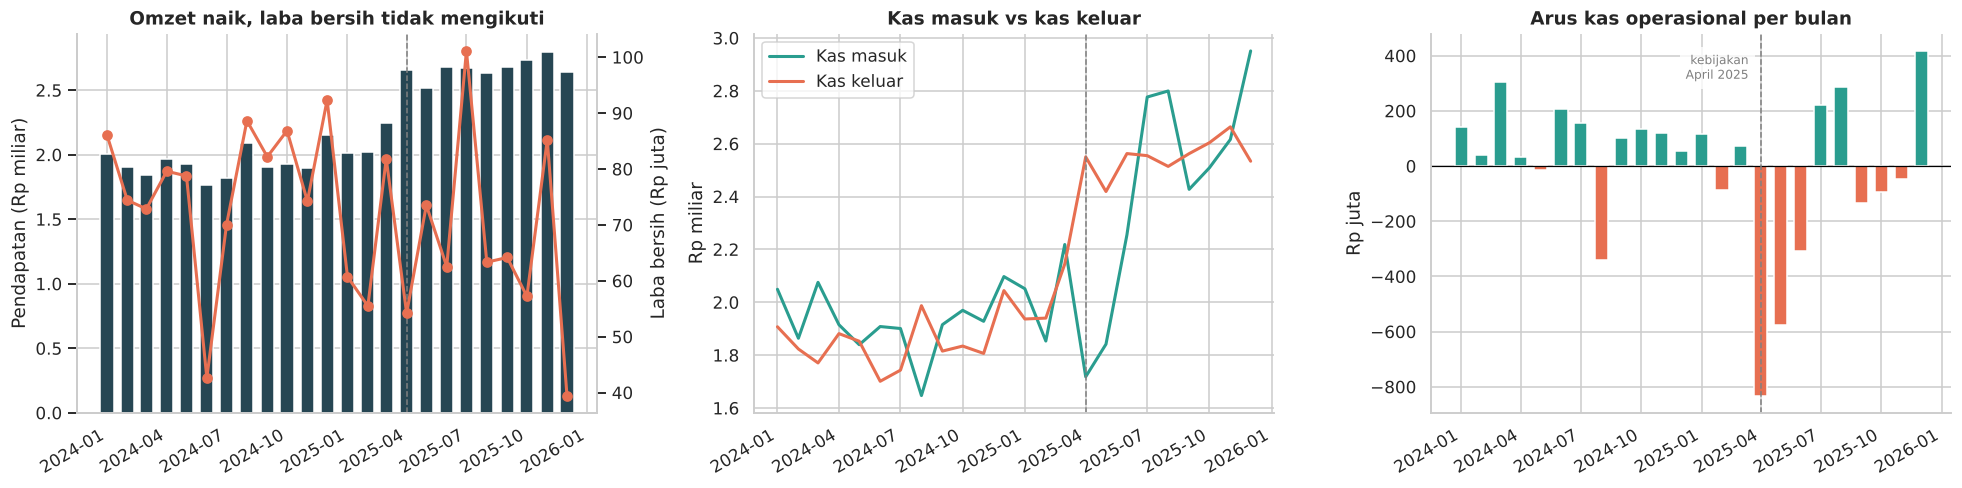

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
x = b.index
ax[0].bar(x, b.pendapatan / 1e9, width=20, color=WARNA["biru"], label="Pendapatan")
ax[0].set_ylabel("Pendapatan (Rp miliar)")
a2 = ax[0].twinx(); a2.plot(x, b.laba_bersih / 1e6, color=WARNA["merah"], marker="o", lw=2, label="Laba bersih"); a2.set_ylabel("Laba bersih (Rp juta)")
a2.spines["right"].set_visible(True); a2.grid(False)
ax[0].set_title("Omzet naik, laba bersih tidak mengikuti")

ax[1].plot(x, b.kas_masuk / 1e9, label="Kas masuk", color=WARNA["hijau"], lw=2)
ax[1].plot(x, b.kas_keluar / 1e9, label="Kas keluar", color=WARNA["merah"], lw=2)
ax[1].set_title("Kas masuk vs kas keluar"); ax[1].set_ylabel("Rp miliar"); ax[1].legend()

ax[2].bar(x, b.arus_kas_operasional / 1e6, width=20, color=np.where(b.arus_kas_operasional >= 0, WARNA["hijau"], WARNA["merah"]))
ax[2].axhline(0, color="black", lw=.8); ax[2].set_title("Arus kas operasional per bulan"); ax[2].set_ylabel("Rp juta")
for a in ax: a.axvline(KEBIJAKAN, color="gray", ls="--", lw=1)
ax[2].annotate("kebijakan\nApril 2025", xy=(KEBIJAKAN, ax[2].get_ylim()[1] * 0.85), xytext=(-8, 0), textcoords="offset points",
               ha="right", va="top", fontsize=8, color="gray", bbox=dict(fc="white", ec="none", alpha=.8))
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

---
## 5. Analitik Diagnostik — *Mengapa hal itu terjadi?*

Dugaan manajemen (dari kuliah): **diskon berlebihan, pelonggaran batas kredit ke pelanggan berisiko, dan penagihan lemah**. Kita uji dengan data, bukan percaya begitu saja.

### 5.1 Dekomposisi perubahan laba bersih (*profit bridge*)
Selisih laba 2025 − 2024 dipecah menjadi: efek **volume**, efek **diskon**, efek **bauran produk** (margin sebelum diskon), perubahan **beban operasional**, dan **piutang macet**.

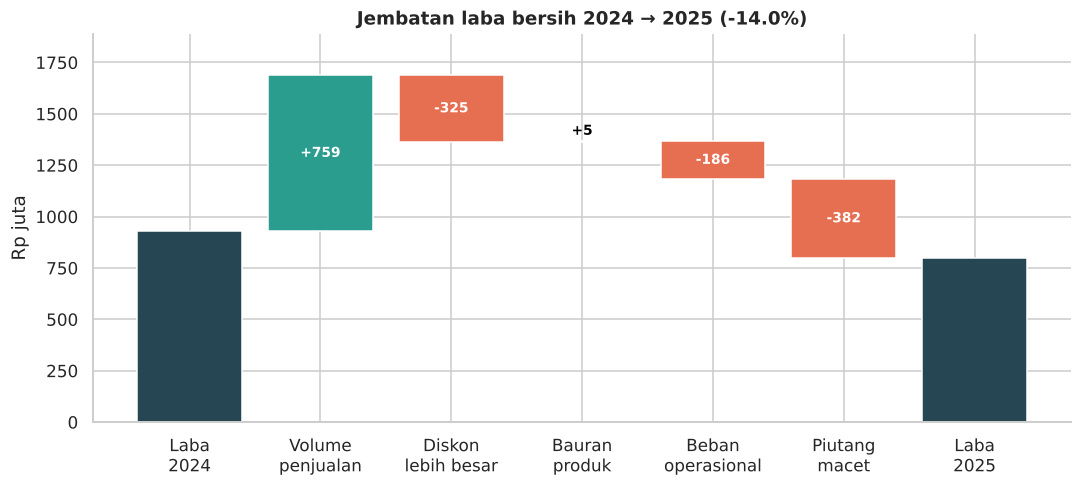

Volume menambah Rp 758.9 jt, tetapi diskon (Rp -325.0 jt), piutang macet (Rp -382.4 jt) dan beban operasional (Rp -186.0 jt) menggerus lebih banyak.


In [9]:
th = analisis.groupby("tahun").agg(lst=("nilai_list", "sum"), net=("nilai_faktur", "sum"), hpp=("hpp_total", "sum"))
d_ = 1 - th.net / th.lst                      # rata-rata diskon
m_ = (th.lst - th.hpp) / th.lst               # margin sebelum diskon
vol  = (th.lst[2025] - th.lst[2024]) * (m_[2024] - d_[2024])
disk = -th.lst[2025] * (d_[2025] - d_[2024])
mix  = th.lst[2025] * (m_[2025] - m_[2024])
d_opex = -(K.loc["Beban operasional", 2025] - K.loc["Beban operasional", 2024])
d_bd   = -(K.loc["Piutang macet", 2025] - K.loc["Piutang macet", 2024])
np24, np25 = K.loc["Laba bersih", 2024], K.loc["Laba bersih", 2025]
assert np.isclose(vol + disk + mix + d_opex + d_bd, np25 - np24), "Dekomposisi harus cocok dengan selisih laba"

komponen = [("Volume\npenjualan", vol), ("Diskon\nlebih besar", disk), ("Bauran\nproduk", mix),
            ("Beban\noperasional", d_opex), ("Piutang\nmacet", d_bd)]
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(0, np24 / 1e6, color=WARNA["biru"])
kum = np24
for i, (lab, v) in enumerate(komponen, start=1):
    ax.bar(i, v / 1e6, bottom=kum / 1e6, color=WARNA["hijau"] if v >= 0 else WARNA["merah"])
    if abs(v) / 1e6 >= 60:
        ax.text(i, (kum + v / 2) / 1e6, f"{v/1e6:+,.0f}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    else:                                               # bar kecil: label di atas bar
        ax.text(i, max(kum, kum + v) / 1e6 + 15, f"{v/1e6:+,.0f}", ha="center", va="bottom", color="black", fontsize=9, fontweight="bold")
    kum += v
ax.bar(len(komponen) + 1, np25 / 1e6, color=WARNA["biru"])
ax.set_xticks(range(len(komponen) + 2)); ax.set_xticklabels(["Laba\n2024"] + [k[0] for k in komponen] + ["Laba\n2025"])
ax.set_ylim(0, (max(np24, np25, np24 + max(vol, 0), np24 + vol + disk + max(mix, 0)) / 1e6) * 1.12)
ax.set_ylabel("Rp juta"); ax.set_title(f"Jembatan laba bersih 2024 → 2025 ({pct(np25/np24-1)})")
plt.tight_layout(); plt.show()
print(f"Volume menambah {rp_jt(vol)}, tetapi diskon ({rp_jt(disk)}), piutang macet ({rp_jt(d_bd)}) dan beban operasional ({rp_jt(d_opex)}) menggerus lebih banyak.")

### 5.2 Uji tiga dugaan: kredit, diskon, penagihan

(1) Kredit & risiko pelanggan, sebelum vs sesudah kebijakan


,periode,rating_kredit,faktur,porsi penjualan,limit_rata2 (jt),% macet (nilai)
0,Sebelum kebijakan,A,2758,54.62,39.35,0.17
1,Sebelum kebijakan,B,1664,30.82,21.11,0.49
2,Sebelum kebijakan,C,774,14.57,12.01,2.60
3,Sesudah kebijakan,A,1901,46.95,79.06,0.88
4,Sesudah kebijakan,B,1326,30.56,42.71,0.81
5,Sesudah kebijakan,C,1014,22.49,24.47,5.44



(3) Disiplin pembayaran (hanya faktur yang sudah dibayar)


,rata-rata hari telat,% faktur telat > 7 hari
periode,,
Sebelum kebijakan,3.05,12.18
Sesudah kebijakan,8.71,30.38


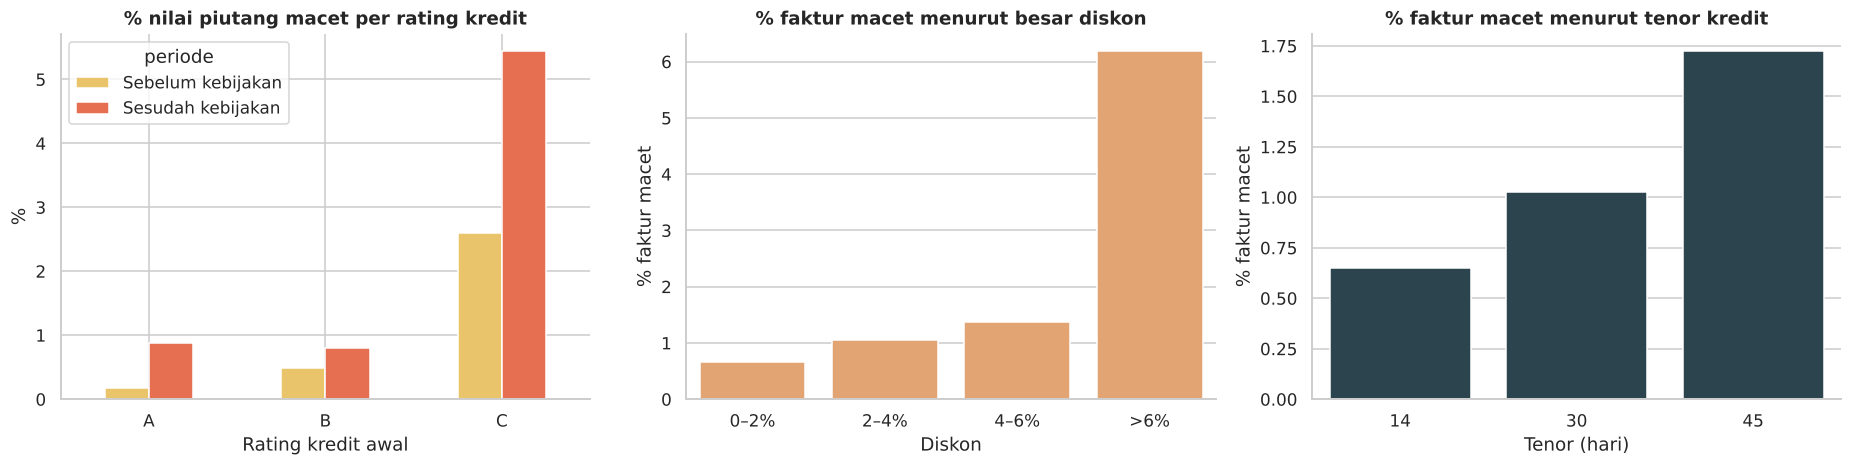

In [10]:
a = analisis.copy()
a["nilai_macet"] = a.nilai_faktur * a.macet
urut = ["Sebelum kebijakan", "Sesudah kebijakan"]

# (1) Pelonggaran kredit ke pelanggan berisiko
t1 = a.groupby(["periode", "rating_kredit"]).agg(faktur=("invoice_id", "count"), nilai=("nilai_faktur", "sum"),
                                                  macet=("nilai_macet", "sum"), limit_rata2=("limit_kredit", "mean")).reset_index()
t1["% macet (nilai)"] = t1.macet / t1.nilai * 100
t1["porsi penjualan"] = t1.nilai / t1.groupby("periode").nilai.transform("sum") * 100
t1["limit_rata2 (jt)"] = t1.limit_rata2 / 1e6
print("(1) Kredit & risiko pelanggan, sebelum vs sesudah kebijakan")
display(t1[["periode", "rating_kredit", "faktur", "porsi penjualan", "limit_rata2 (jt)", "% macet (nilai)"]].round(2))

# (2) Diskon
a["bucket_diskon"] = pd.cut(a.diskon_pct, [-0.001, 0.02, 0.04, 0.06, 0.2], labels=["0–2%", "2–4%", "4–6%", ">6%"])
t2 = a.groupby("bucket_diskon", observed=True).agg(faktur=("invoice_id", "count"), macet=("macet", "mean")).reset_index()
t2["% faktur macet"] = t2.macet * 100

# (3) Penagihan & tenor
bayar = a[a.dibayar]
t3 = bayar.groupby("periode").agg(rata2_telat=("hari_telat", lambda s: s.clip(lower=0).mean()),
                                  pct_telat_7=("hari_telat", lambda s: (s > 7).mean() * 100)).reindex(urut)
t4 = a.groupby("term_hari").agg(faktur=("invoice_id", "count"), macet=("macet", "mean")).reset_index()
t4["% faktur macet"] = t4.macet * 100
print("\n(3) Disiplin pembayaran (hanya faktur yang sudah dibayar)")
display(t3.rename(columns={"rata2_telat": "rata-rata hari telat", "pct_telat_7": "% faktur telat > 7 hari"}).round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
pv = t1.pivot(index="rating_kredit", columns="periode", values="% macet (nilai)")[urut]
pv.plot.bar(ax=ax[0], color=[WARNA["kuning"], WARNA["merah"]], rot=0); ax[0].set_title("% nilai piutang macet per rating kredit"); ax[0].set_xlabel("Rating kredit awal"); ax[0].set_ylabel("%")
sns.barplot(data=t2, x="bucket_diskon", y="% faktur macet", color=WARNA["oranye"], ax=ax[1]); ax[1].set_title("% faktur macet menurut besar diskon"); ax[1].set_xlabel("Diskon")
sns.barplot(data=t4, x="term_hari", y="% faktur macet", color=WARNA["biru"], ax=ax[2]); ax[2].set_title("% faktur macet menurut tenor kredit"); ax[2].set_xlabel("Tenor (hari)")
plt.tight_layout(); plt.show()

In [11]:
c_pre, c_post = t1[(t1.rating_kredit == "C")].set_index("periode").loc[urut, "porsi penjualan"]
l_pre, l_post = a.groupby("periode").limit_kredit.mean().loc[urut] / 1e6
print("Temuan diagnostik:")
print(f"• Porsi penjualan ke pelanggan rating C: {c_pre:.1f}% → {c_post:.1f}%; rata-rata batas kredit {l_pre:.1f} jt → {l_post:.1f} jt.")
print(f"• Rata-rata diskon {d_[2024]*100:.2f}% (2024) → {d_[2025]*100:.2f}% (2025); faktur dengan diskon >6% macet {t2.iloc[-1]['% faktur macet']:.1f}% vs {t2.iloc[0]['% faktur macet']:.1f}% pada diskon 0–2%.")
print(f"• Faktur tenor 45 hari macet {t4.set_index('term_hari').loc[45, '% faktur macet']:.1f}% vs {t4.set_index('term_hari').loc[14, '% faktur macet']:.1f}% untuk tenor 14 hari.")
print(f"• Rata-rata keterlambatan bayar {t3.loc[urut[0], 'rata2_telat']:.1f} → {t3.loc[urut[1], 'rata2_telat']:.1f} hari; DSO {K.loc['DSO (hari)',2024]:.0f} → {K.loc['DSO (hari)',2025]:.0f} hari.")
print("\n⚠️ Hati-hati menafsirkan: korelasi bukan sebab-akibat. Diskon terbesar justru banyak diberikan ke pelanggan berisiko tinggi (confounding), jadi sebagian dari angka diskon di atas sebenarnya efek risiko pelanggan. Di Bagian 6 model memisahkan pengaruh tiap faktor.")
print("\nKesimpulan: omzet naik karena 'dibeli' dengan diskon, kredit longgar, dan tenor panjang; sebagian omzet itu berasal dari pelanggan yang tidak membayar.")

Temuan diagnostik:
• Porsi penjualan ke pelanggan rating C: 14.6% → 22.5%; rata-rata batas kredit 29.4 jt → 54.6 jt.
• Rata-rata diskon 2.08% (2024) → 3.12% (2025); faktur dengan diskon >6% macet 6.2% vs 0.7% pada diskon 0–2%.
• Faktur tenor 45 hari macet 1.7% vs 0.7% untuk tenor 14 hari.
• Rata-rata keterlambatan bayar 3.1 → 8.7 hari; DSO 29 → 44 hari.

⚠️ Hati-hati menafsirkan: korelasi bukan sebab-akibat. Diskon terbesar justru banyak diberikan ke pelanggan berisiko tinggi (confounding), jadi sebagian dari angka diskon di atas sebenarnya efek risiko pelanggan. Di Bagian 6 model memisahkan pengaruh tiap faktor.

Kesimpulan: omzet naik karena 'dibeli' dengan diskon, kredit longgar, dan tenor panjang; sebagian omzet itu berasal dari pelanggan yang tidak membayar.


---
## 6. Analitik Prediktif — *Apa yang kemungkinan akan terjadi?*  *(CRISP-DM tahap 4: Modeling)*

**Tujuan model:** memberi **skor risiko macet** pada setiap faktur baru *sebelum* barang dikirim.

**Kebocoran data (*data leakage*)** adalah jebakan terbesar. Fitur hanya boleh memakai informasi yang **sudah diketahui pada tanggal faktur**. Karena itu, riwayat pembayaran dihitung dari faktur lama yang hasilnya *sudah terlihat* pada tanggal tersebut.

**Pembagian data berdasarkan waktu** (bukan acak): latih pada faktur sebelum 1 Juli 2025, uji pada Juli–Desember 2025, seperti kondisi nyata (model dipakai untuk masa depan). *(Penyederhanaan: label macet dianggap sudah diketahui semua pada saat pelatihan.)*

In [12]:
def tambah_riwayat(df):
    """Fitur riwayat per pelanggan yang hanya memakai informasi yang sudah diketahui pada tanggal faktur."""
    df = df.sort_values(["customer_id", "tanggal", "invoice_id"]).reset_index(drop=True)
    hasil = np.zeros((len(df), 4))
    for _, idx in df.groupby("customer_id").indices.items():
        g = df.iloc[idx]
        t   = g.tanggal.values.astype("datetime64[D]")
        byr = g.tanggal_bayar.values.astype("datetime64[D]")
        jt  = g.jatuh_tempo.values.astype("datetime64[D]")
        telat = (g.hari_telat.fillna(0).values > 7)
        n = len(g)
        lebih_awal = np.tril(np.ones((n, n), bool), -1)                   # faktur j yang terbit sebelum faktur i
        sudah_lunas = lebih_awal & (byr[None, :] <= t[:, None])            # hasilnya sudah terlihat pada tanggal i
        macet_terlihat = lebih_awal & ((jt + np.timedelta64(60, "D"))[None, :] < t[:, None]) & ~(byr[None, :] <= t[:, None])
        n_lunas = sudah_lunas.sum(1)
        n_telat = (sudah_lunas & telat[None, :]).sum(1)
        hasil[idx, 0] = lebih_awal.sum(1)
        hasil[idx, 1] = n_telat
        hasil[idx, 2] = n_telat / np.maximum(n_lunas, 1)
        hasil[idx, 3] = macet_terlihat.sum(1)
    df[["n_riwayat", "n_telat_riwayat", "rasio_telat", "n_macet_terlihat"]] = hasil
    df["rasio_eksposur"] = (df.piutang_berjalan + df.nilai_faktur) / df.limit_kredit
    return df

data_ml = tambah_riwayat(faktur.copy())
NUM  = ["nilai_faktur", "diskon_pct", "term_hari", "limit_kredit", "piutang_berjalan", "rasio_eksposur",
        "lama_langganan_bln", "n_item", "n_riwayat", "n_telat_riwayat", "rasio_telat", "n_macet_terlihat"]
KAT  = ["rating_kredit", "jenis_usaha"]
FITUR = NUM + KAT

CUT = pd.Timestamp("2025-07-01")
train, test = data_ml[data_ml.tanggal < CUT], data_ml[data_ml.tanggal >= CUT]
Xtr, ytr = train[FITUR], train.macet.astype(int).values
Xte, yte = test[FITUR],  test.macet.astype(int).values
print(pd.DataFrame({"jumlah faktur": [len(train), len(test)], "faktur macet": [ytr.sum(), yte.sum()],
                    "% macet": [ytr.mean() * 100, yte.mean() * 100]}, index=["Latih (< Jul 2025)", "Uji (Jul–Des 2025)"]).round(2))
print("Catatan: kelas sangat tidak seimbang dan tingkat macet pada data uji LEBIH TINGGI (pergeseran distribusi akibat kebijakan).")

                    jumlah faktur  faktur macet  % macet
Latih (< Jul 2025)           7257            62     0.85
Uji (Jul–Des 2025)           2850            54     1.89
Catatan: kelas sangat tidak seimbang dan tingkat macet pada data uji LEBIH TINGGI (pergeseran distribusi akibat kebijakan).


In [13]:
pre_lr = ColumnTransformer([("num", StandardScaler(), NUM), ("kat", OneHotEncoder(handle_unknown="ignore"), KAT)])
pre_rf = ColumnTransformer([("num", "passthrough", NUM),    ("kat", OneHotEncoder(handle_unknown="ignore"), KAT)])
kandidat = {
    "Regresi Logistik": Pipeline([("pre", pre_lr), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "Random Forest":    Pipeline([("pre", pre_rf), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                    class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1))]),
}

def recall_top(y, skor, frac=0.10):
    k = int(len(y) * frac); idx = np.argsort(-skor)[:k]
    return y[idx].sum() / y.sum()

skor, hasil = {}, []
for nama, mdl in kandidat.items():
    mdl.fit(Xtr, ytr)
    skor[nama] = mdl.predict_proba(Xte)[:, 1]
    hasil.append({"Model": nama, "ROC-AUC": roc_auc_score(yte, skor[nama]), "PR-AUC (Avg Precision)": average_precision_score(yte, skor[nama]),
                  "Recall di 10% skor tertinggi": recall_top(yte, skor[nama], .10), "Recall di 20% skor tertinggi": recall_top(yte, skor[nama], .20)})
evaluasi = pd.DataFrame(hasil).set_index("Model")
display(evaluasi.round(3))
print(f"Pembanding acak: ROC-AUC 0.50, PR-AUC ≈ {yte.mean():.3f}, recall di 10% teratas ≈ 0.10")

,ROC-AUC,PR-AUC (Avg Precision),Recall di 10% skor tertinggi,Recall di 20% skor tertinggi
Model,,,,
Regresi Logistik,0.79,0.12,0.50,0.69
Random Forest,0.75,0.10,0.50,0.63


Pembanding acak: ROC-AUC 0.50, PR-AUC ≈ 0.019, recall di 10% teratas ≈ 0.10


### 6.1 Evaluasi *(CRISP-DM tahap 5)*
Pada data yang sangat tidak seimbang, **akurasi menyesatkan** (menebak "tidak macet" untuk semua faktur sudah akurat >95%). Kita pakai **PR-AUC** dan **recall pada sebagian kecil faktur yang ditandai**, ukuran yang sesuai kebutuhan bisnis: *tandai sedikit faktur, tangkap banyak kasus macet.*

Model terbaik menurut PR-AUC: Regresi Logistik
Model final (terkalibrasi): ROC-AUC 0.777 | PR-AUC 0.101 | recall@10% 0.43


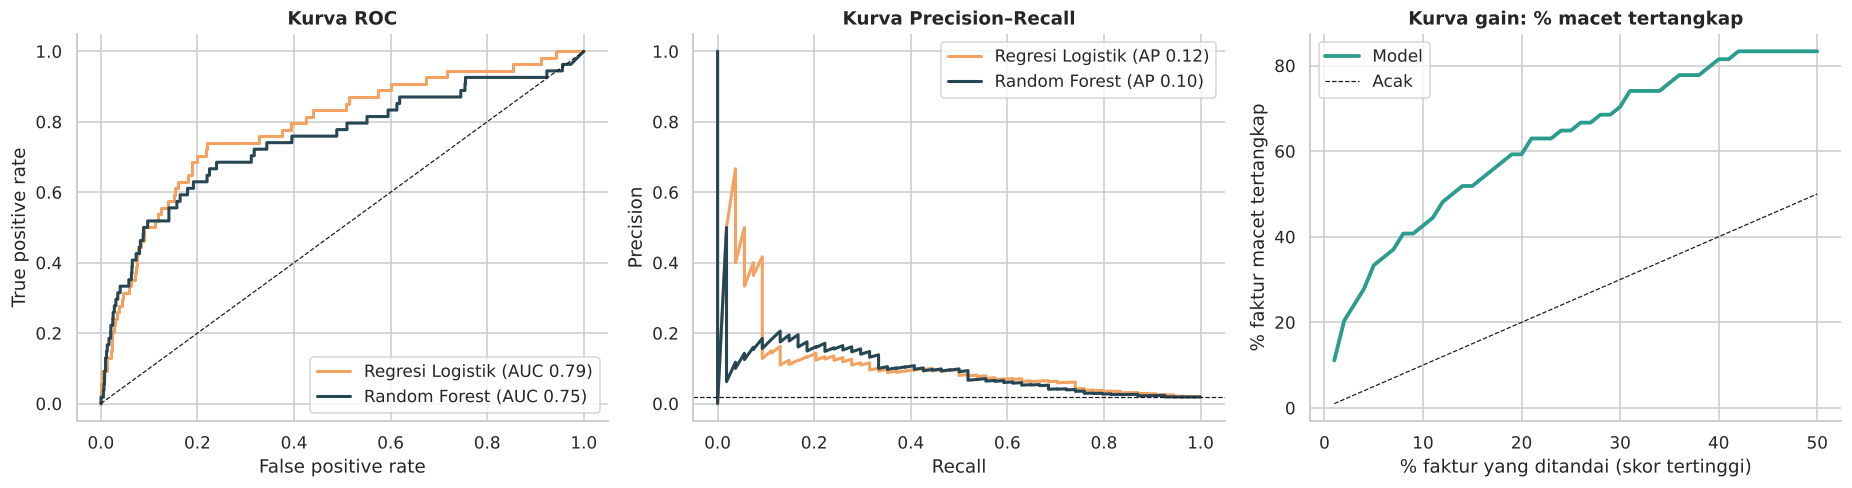

In [14]:
terbaik = evaluasi["PR-AUC (Avg Precision)"].idxmax()
print("Model terbaik menurut PR-AUC:", terbaik)

# Kalibrasi probabilitas supaya skor dapat dibaca sebagai peluang
model_final = CalibratedClassifierCV(clone(kandidat[terbaik]), method="sigmoid", cv=3).fit(Xtr, ytr)
skor_te = model_final.predict_proba(Xte)[:, 1]
print(f"Model final (terkalibrasi): ROC-AUC {roc_auc_score(yte, skor_te):.3f} | PR-AUC {average_precision_score(yte, skor_te):.3f} | "
      f"recall@10% {recall_top(yte, skor_te, .10):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (nama, s), warna in zip(skor.items(), [WARNA["oranye"], WARNA["biru"]]):
    fpr, tpr, _ = roc_curve(yte, s); ax[0].plot(fpr, tpr, label=f"{nama} (AUC {roc_auc_score(yte, s):.2f})", color=warna, lw=2)
    p, r, _ = precision_recall_curve(yte, s); ax[1].plot(r, p, label=f"{nama} (AP {average_precision_score(yte, s):.2f})", color=warna, lw=2)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("Kurva ROC"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
ax[1].axhline(yte.mean(), color="k", ls="--", lw=.8); ax[1].set_title("Kurva Precision–Recall"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()

fr = np.linspace(0.01, 0.5, 50)
ax[2].plot(fr * 100, [recall_top(yte, skor_te, f) * 100 for f in fr], color=WARNA["hijau"], lw=2.5, label="Model")
ax[2].plot(fr * 100, fr * 100, "k--", lw=.8, label="Acak")
ax[2].set_title("Kurva gain: % macet tertangkap"); ax[2].set_xlabel("% faktur yang ditandai (skor tertinggi)"); ax[2].set_ylabel("% faktur macet tertangkap"); ax[2].legend()
plt.tight_layout(); plt.show()

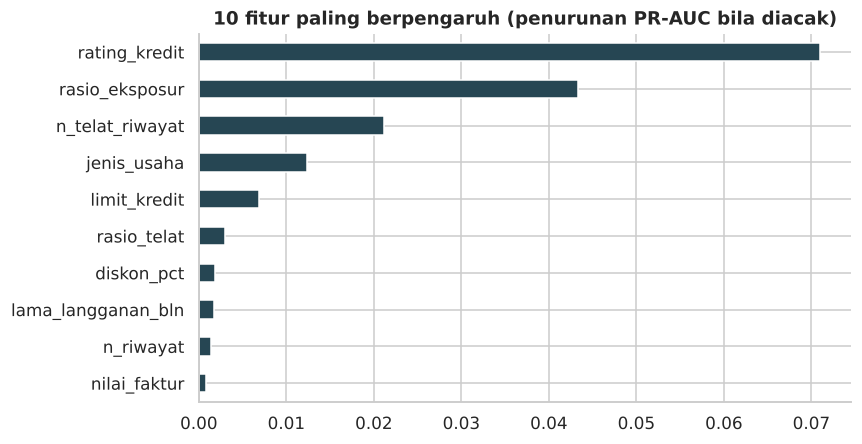

Tiga faktor teratas: rating_kredit, rasio_eksposur, n_telat_riwayat.
'diskon_pct' berada di peringkat 7 dari 14: setelah rating dan eksposur kredit diperhitungkan, diskon bukan faktor utama. Jadi sebagian 'efek diskon' di Bagian 5 sebenarnya efek pelanggan berisiko yang diberi diskon besar.
Ekspektasi piutang macet Jul–Des 2025 menurut model : Rp 0.26 M
Realisasi piutang macet                              : Rp 0.32 M
→ Model cenderung meremehkan kerugian (rasio ekspektasi/realisasi = 0.80) karena tingkat macet berubah sesudah kebijakan (concept drift). Model harus dipantau dan dilatih ulang berkala.


In [15]:
# Faktor apa yang paling menentukan skor? (permutation importance pada data uji)
pi = permutation_importance(model_final, Xte, yte, scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FITUR).sort_values(ascending=True).tail(10)
ax = imp.plot.barh(figsize=(8, 4.2), color=WARNA["biru"]); ax.set_title("10 fitur paling berpengaruh (penurunan PR-AUC bila diacak)")
plt.tight_layout(); plt.show()
imp_all = pd.Series(pi.importances_mean, index=FITUR).sort_values(ascending=False)
rank_diskon = list(imp_all.index).index("diskon_pct") + 1
print(f"Tiga faktor teratas: {', '.join(imp_all.index[:3])}.")
if rank_diskon > 3:
    print(f"'diskon_pct' berada di peringkat {rank_diskon} dari {len(FITUR)}: setelah rating dan eksposur kredit diperhitungkan, diskon bukan faktor utama. "
          "Jadi sebagian 'efek diskon' di Bagian 5 sebenarnya efek pelanggan berisiko yang diberi diskon besar.")
else:
    print(f"'diskon_pct' termasuk 3 faktor teratas (peringkat {rank_diskon}), jadi diskon besar memang ikut menaikkan risiko macet.")

# Sanity check kalibrasi: apakah total ekspektasi kerugian sama dengan realita?
ekspektasi = (skor_te * test.nilai_faktur.values).sum(); aktual = test.loc[test.macet, "nilai_faktur"].sum()
print(f"Ekspektasi piutang macet Jul–Des 2025 menurut model : {rp_m(ekspektasi)}")
print(f"Realisasi piutang macet                              : {rp_m(aktual)}")
arah = "meremehkan" if ekspektasi < aktual else "melebih-lebihkan"
print(f"→ Model cenderung {arah} kerugian (rasio ekspektasi/realisasi = {ekspektasi/aktual:.2f}) karena tingkat macet berubah sesudah kebijakan (concept drift). Model harus dipantau dan dilatih ulang berkala.")

---
## 7. Analitik Preskriptif — *Apa yang sebaiknya dilakukan?*

Prediksi saja belum cukup. Kita ubah skor menjadi **keputusan** dan hitung manfaatnya dengan *backtest* pada Juli–Desember 2025.

**Kebijakan yang diuji:** faktur dengan skor tertinggi diwajibkan **uang muka (DP) 50%**.
**Asumsi (bisa diubah):**
* Pelanggan yang diminta DP bisa **membatalkan pembelian** dengan peluang `CHURN`.
* Faktur macet menimbulkan kerugian sebesar HPP barang yang sudah dikirim.
* Jika pelanggan menerima DP lalu tetap macet, kerugian berkurang sebesar DP yang diterima.

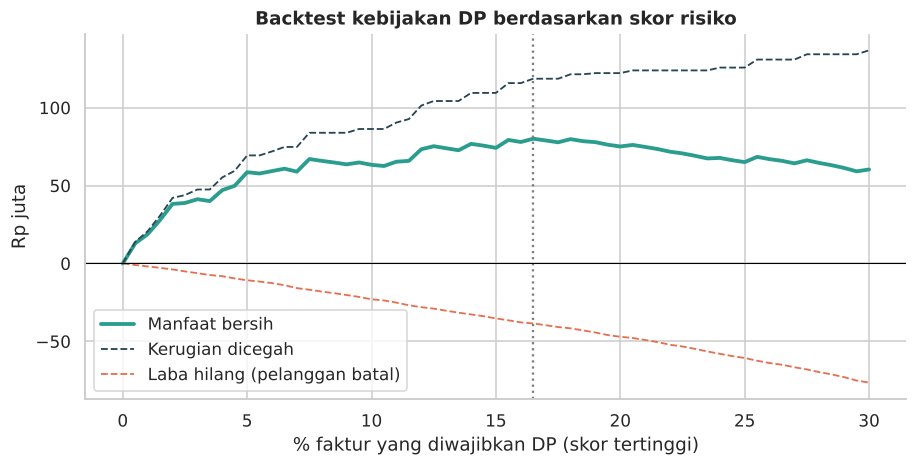

Rekomendasi: wajibkan DP 50% pada ±16.5% faktur dengan skor tertinggi (skor ≥ 0.024).
Estimasi manfaat bersih semester II 2025: Rp 80.1 jt (kerugian dicegah Rp 118.6 jt, laba hilang Rp 38.5 jt).


In [16]:
DP_PERSEN = 0.50     # ← ubah sesuai kebijakan
CHURN     = 0.20     # ← peluang pelanggan batal beli bila diminta DP

uji = test.assign(skor=skor_te).reset_index(drop=True)
uji = uji.sort_values("skor", ascending=False).reset_index(drop=True)

def manfaat(frac):
    k = int(len(uji) * frac); f = uji.iloc[:k]
    m, n = f[f.macet], f[~f.macet]
    hindar = ((1 - CHURN) * DP_PERSEN * m.nilai_faktur + CHURN * m.hpp_total).sum()   # kerugian yang dicegah
    biaya  = (CHURN * n.laba_kotor).sum()                                             # laba hilang dari pelanggan baik yang batal
    return hindar - biaya, hindar, biaya

grid = np.arange(0.0, 0.301, 0.005)
kurva = pd.DataFrame([(f, *manfaat(f)) for f in grid], columns=["frac", "manfaat_bersih", "kerugian_dicegah", "laba_hilang"])
best = kurva.loc[kurva.manfaat_bersih.idxmax()]
TAU = uji.skor.iloc[int(len(uji) * best.frac) - 1]

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(kurva.frac * 100, kurva.manfaat_bersih / 1e6, color=WARNA["hijau"], lw=2.5, label="Manfaat bersih")
ax.plot(kurva.frac * 100, kurva.kerugian_dicegah / 1e6, color=WARNA["biru"], lw=1.2, ls="--", label="Kerugian dicegah")
ax.plot(kurva.frac * 100, -kurva.laba_hilang / 1e6, color=WARNA["merah"], lw=1.2, ls="--", label="Laba hilang (pelanggan batal)")
ax.axvline(best.frac * 100, color="gray", ls=":"); ax.axhline(0, color="black", lw=.7)
ax.set_xlabel("% faktur yang diwajibkan DP (skor tertinggi)"); ax.set_ylabel("Rp juta"); ax.set_title("Backtest kebijakan DP berdasarkan skor risiko"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Rekomendasi: wajibkan DP {DP_PERSEN:.0%} pada ±{best.frac*100:.1f}% faktur dengan skor tertinggi (skor ≥ {TAU:.3f}).")
print(f"Estimasi manfaat bersih semester II 2025: {rp_jt(best.manfaat_bersih)} (kerugian dicegah {rp_jt(best.kerugian_dicegah)}, laba hilang {rp_jt(best.laba_hilang)}).")

In [17]:
# Rekomendasi per pelanggan (tingkat tindakan)
pel = uji.groupby("customer_id").agg(rating=("rating_kredit", "first"), faktur=("invoice_id", "count"), nilai=("nilai_faktur", "sum"),
                                    skor_rata2=("skor", "mean"), skor_maks=("skor", "max"), macet=("macet", "sum"),
                                    limit_kini=("limit_kredit", "last")).reset_index()
q_hi, q_mid = pel.skor_rata2.quantile(.95), pel.skor_rata2.quantile(.80)
def tindakan(r):
    if r.skor_rata2 >= q_hi:  return "TINJAU: turunkan limit 50% + wajib DP"
    if r.skor_rata2 >= q_mid: return "PANTAU: tenor maks 30 hari, tagih H-3 & H+7"
    return "PERTAHANKAN"
pel["tindakan"] = pel.apply(tindakan, axis=1)
pel["limit_usulan (jt)"] = np.where(pel.tindakan.str.startswith("TINJAU"), pel.limit_kini * 0.5, pel.limit_kini) / 1e6
print("Top 12 pelanggan menurut skor risiko rata-rata (Jul–Des 2025):")
display(pel.sort_values("skor_rata2", ascending=False).head(12)[["customer_id", "rating", "faktur", "nilai", "skor_rata2", "macet", "tindakan", "limit_usulan (jt)"]]
        .assign(nilai=lambda d: d.nilai / 1e6).rename(columns={"nilai": "nilai (jt)"}).round(3))
print("\nSebaran tindakan:"); print(pel.tindakan.value_counts().to_string())

Top 12 pelanggan menurut skor risiko rata-rata (Jul–Des 2025):


,customer_id,rating,faktur,nilai (jt),skor_rata2,macet,tindakan,limit_usulan (jt)
305,C0308,C,15,102.25,0.08,3,TINJAU: turunkan limit 50% + wajib DP,14.00
61,C0064,C,16,81.39,0.08,3,TINJAU: turunkan limit 50% + wajib DP,13.00
152,C0155,C,25,161.56,0.08,3,TINJAU: turunkan limit 50% + wajib DP,19.00
203,C0206,C,13,44.83,0.05,1,TINJAU: turunkan limit 50% + wajib DP,12.00
267,C0270,C,19,167.56,0.05,4,TINJAU: turunkan limit 50% + wajib DP,14.00
227,C0230,C,16,123.12,0.05,0,TINJAU: turunkan limit 50% + wajib DP,15.00
64,C0067,C,14,52.28,0.04,0,TINJAU: turunkan limit 50% + wajib DP,12.00
299,C0302,C,11,47.95,0.04,1,TINJAU: turunkan limit 50% + wajib DP,12.00
50,C0053,C,19,151.29,0.04,3,TINJAU: turunkan limit 50% + wajib DP,13.00
110,C0113,C,16,65.59,0.04,1,TINJAU: turunkan limit 50% + wajib DP,12.00



Sebaran tindakan:
tindakan
PERTAHANKAN                                    254
PANTAU: tenor maks 30 hari, tagih H-3 & H+7     48
TINJAU: turunkan limit 50% + wajib DP           16


In [18]:
# Ringkasan kebijakan (setiap baris didukung angka dari analisis di atas)
hi_d, lo_d = t2.iloc[-1]["% faktur macet"], t2.iloc[0]["% faktur macet"]
r_c = t1[(t1.rating_kredit == "C") & (t1.periode == "Sesudah kebijakan")]["% macet (nilai)"].iloc[0]
kebijakan_tbl = pd.DataFrame([
    ["1", "Batasi diskon maksimum 4–5% (di atas itu butuh persetujuan direktur)", f"Faktur diskon >6% macet {hi_d:.1f}% vs {lo_d:.1f}% pada diskon 0–2%", "Rata-rata diskon, margin kotor"],
    ["2", "Kembalikan batas kredit rating C ke level sebelum April 2025", f"Rating C: {r_c:.1f}% nilai piutang macet setelah pelonggaran", "% macet per rating, porsi penjualan rating C"],
    ["3", f"Wajib DP {DP_PERSEN:.0%} untuk faktur skor tinggi (≈{best.frac*100:.0f}% faktur)", f"Backtest: manfaat bersih {rp_jt(best.manfaat_bersih)} per semester", "Recall model, laba hilang akibat pembatalan"],
    ["4", "Disiplin penagihan: pengingat H-3 dan H+7, eskalasi H+21", f"DSO {K.loc['DSO (hari)',2024]:.0f} → {K.loc['DSO (hari)',2025]:.0f} hari", "DSO, % faktur telat > 7 hari"],
    ["5", "Latih ulang model tiap kuartal dan pantau pergeseran distribusi", "Model meremehkan kerugian setelah kebijakan berubah", "PR-AUC, selisih ekspektasi vs realisasi"],
], columns=["#", "Tindakan", "Dasar data", "KPI pemantauan"]).set_index("#")
pd.set_option("display.max_colwidth", 120)
display(kebijakan_tbl)

,Tindakan,Dasar data,KPI pemantauan
#,,,
1,Batasi diskon maksimum 4–5% (di atas itu butuh persetujuan direktur),Faktur diskon >6% macet 6.2% vs 0.7% pada diskon 0–2%,"Rata-rata diskon, margin kotor"
2,Kembalikan batas kredit rating C ke level sebelum April 2025,Rating C: 5.4% nilai piutang macet setelah pelonggaran,"% macet per rating, porsi penjualan rating C"
3,Wajib DP 50% untuk faktur skor tinggi (≈16% faktur),Backtest: manfaat bersih Rp 80.1 jt per semester,"Recall model, laba hilang akibat pembatalan"
4,"Disiplin penagihan: pengingat H-3 dan H+7, eskalasi H+21",DSO 29 → 44 hari,"DSO, % faktur telat > 7 hari"
5,Latih ulang model tiap kuartal dan pantau pergeseran distribusi,Model meremehkan kerugian setelah kebijakan berubah,"PR-AUC, selisih ekspektasi vs realisasi"


---
## 8. Market Basket Analysis — *produk apa yang dibeli bersamaan?*

*Association Rule Mining* dengan **Apriori** / **FP-Growth** mencari pola "pelanggan yang membeli **A** juga membeli **B**". Tiga ukuran utama (sesuai materi):

| Ukuran | Rumus | Arti |
|---|---|---|
| **Support** | P(A ∩ B) | seberapa sering kombinasi muncul di seluruh transaksi |
| **Confidence** | P(A ∩ B) / P(A) | seberapa sering B dibeli *ketika* A dibeli |
| **Lift** | P(A ∩ B) / (P(A)·P(B)) | kekuatan asosiasi dibanding bila A dan B tidak berhubungan; **> 1 = asosiasi positif** |

Satu faktur = satu "keranjang".

In [19]:
transaksi = lines[lines.tanggal >= "2024-01-01"]
keranjang = (transaksi.groupby(["invoice_id", "nama_produk"]).size().unstack(fill_value=0) > 0)
print("Matriks keranjang (faktur × produk):", keranjang.shape)

MIN_SUP = 0.03
freq_ap = apriori(keranjang, min_support=MIN_SUP, use_colnames=True)
freq_fp = fpgrowth(keranjang, min_support=MIN_SUP, use_colnames=True)
print(f"Itemset sering — Apriori: {len(freq_ap)} | FP-Growth: {len(freq_fp)}  (hasilnya sama; FP-Growth biasanya lebih cepat pada data besar)")
assert len(freq_ap) == len(freq_fp)

try:      # kompatibel dengan berbagai versi mlxtend
    aturan = association_rules(freq_ap, num_itemsets=len(keranjang), metric="lift", min_threshold=1.0)
except TypeError:
    aturan = association_rules(freq_ap, metric="lift", min_threshold=1.0)

aturan = aturan[(aturan.antecedents.apply(len) == 1) & (aturan.consequents.apply(len) == 1)].copy()
aturan["aturan"] = aturan.antecedents.apply(lambda s: list(s)[0]) + "  →  " + aturan.consequents.apply(lambda s: list(s)[0])
aturan = aturan.sort_values("lift", ascending=False).reset_index(drop=True)
print(f"Aturan 1→1 dengan lift > 1: {len(aturan)}")
display(aturan[["aturan", "support", "confidence", "lift"]].head(12).round(3))

Matriks keranjang (faktur × produk): (9437, 24)
Itemset sering — Apriori: 46 | FP-Growth: 46  (hasilnya sama; FP-Growth biasanya lebih cepat pada data besar)
Aturan 1→1 dengan lift > 1: 36


,aturan,support,confidence,lift
0,Minuman Soda (karton) → Air Mineral (dus),0.06,0.46,3.56
1,Air Mineral (dus) → Minuman Soda (karton),0.06,0.47,3.56
2,Mie Instan (dus) → Kecap Manis (karton),0.06,0.46,3.52
3,Kecap Manis (karton) → Mie Instan (dus),0.06,0.44,3.52
4,Deterjen Bubuk (karton) → Pewangi Pakaian (karton),0.06,0.45,3.46
5,Pewangi Pakaian (karton) → Deterjen Bubuk (karton),0.06,0.45,3.46
6,Air Mineral (dus) → Snack Kentang (karton),0.06,0.46,3.46
7,Snack Kentang (karton) → Air Mineral (dus),0.06,0.45,3.46
8,Beras Premium 25kg → Minyak Goreng 2L (karton),0.06,0.46,3.41
9,Minyak Goreng 2L (karton) → Beras Premium 25kg,0.06,0.44,3.41


Aturan: Minuman Soda (karton) → Air Mineral (dus)
support(A)=0.131  support(B)=0.129  support(A∩B)=0.060
confidence = 0.060/0.131 = 0.459   (mlxtend: 0.459)
lift       = 0.060/(0.131×0.129) = 3.56   (mlxtend: 3.56)


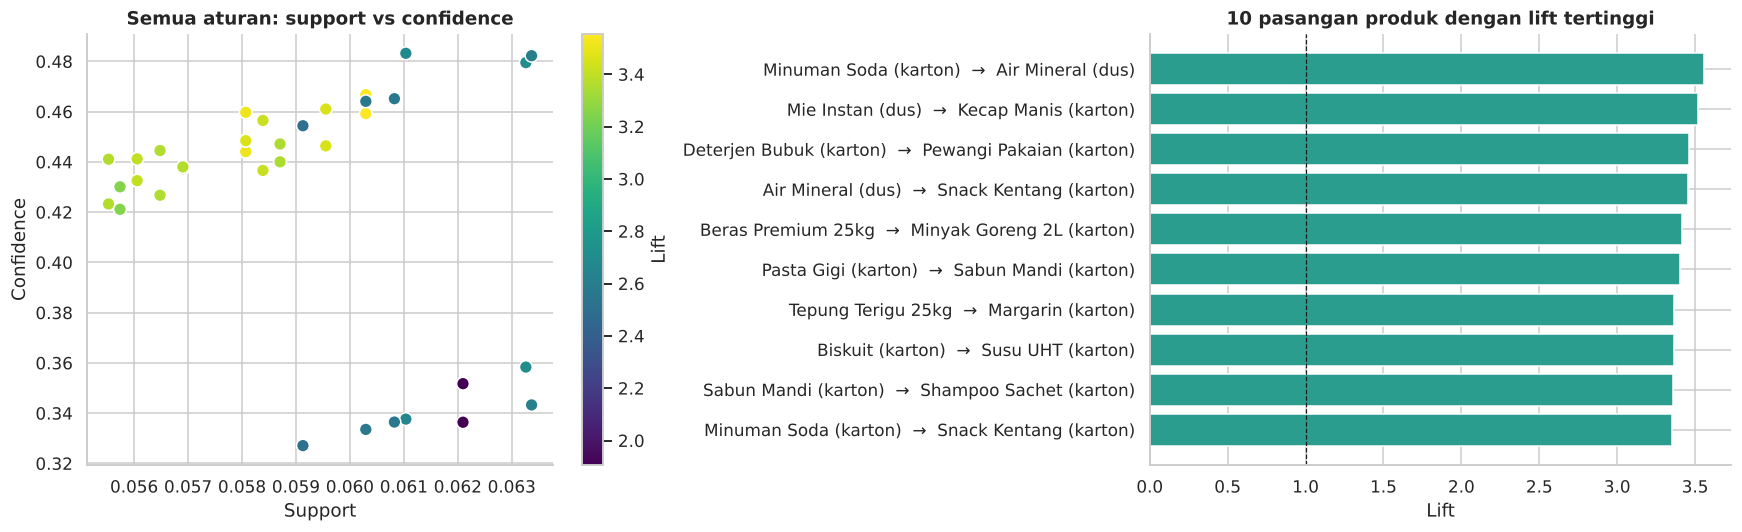

In [20]:
# Verifikasi manual satu aturan (pastikan rumus dipahami, jangan hanya percaya fungsi)
r = aturan.iloc[0]
A, B = list(r.antecedents)[0], list(r.consequents)[0]
sA, sB, sAB = keranjang[A].mean(), keranjang[B].mean(), (keranjang[A] & keranjang[B]).mean()
print(f"Aturan: {A} → {B}")
print(f"support(A)={sA:.3f}  support(B)={sB:.3f}  support(A∩B)={sAB:.3f}")
print(f"confidence = {sAB:.3f}/{sA:.3f} = {sAB/sA:.3f}   (mlxtend: {r.confidence:.3f})")
print(f"lift       = {sAB:.3f}/({sA:.3f}×{sB:.3f}) = {sAB/(sA*sB):.2f}   (mlxtend: {r.lift:.2f})")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sc = ax[0].scatter(aturan.support, aturan.confidence, c=aturan.lift, cmap="viridis", s=70, edgecolor="white")
plt.colorbar(sc, ax=ax[0], label="Lift"); ax[0].set_xlabel("Support"); ax[0].set_ylabel("Confidence"); ax[0].set_title("Semua aturan: support vs confidence")
uniq = aturan.assign(kunci=aturan.apply(lambda x: frozenset(list(x.antecedents) + list(x.consequents)), axis=1)).drop_duplicates("kunci").head(10)
ax[1].barh(uniq.aturan[::-1], uniq.lift[::-1], color=WARNA["hijau"]); ax[1].axvline(1, color="k", lw=.8, ls="--")
ax[1].set_xlabel("Lift"); ax[1].set_title("10 pasangan produk dengan lift tertinggi")
plt.tight_layout(); plt.show()

In [21]:
print("Rekomendasi bundling & cross-selling (maks. 5 pasangan unik):\n")
for i, rr in uniq.head(5).reset_index(drop=True).iterrows():
    a_, b_ = list(rr.antecedents)[0], list(rr.consequents)[0]
    print(f"{i+1}. Paket \"{a_} + {b_}\" — {rr.confidence*100:.0f}% pembeli {a_} juga membeli {b_} (lift {rr.lift:.1f}). "
          f"Tawarkan {b_} saat sales menerima order {a_}; letakkan berdekatan di katalog/gudang.")
print("\nCatatan: lift tinggi = asosiasi kuat, bukan bukti sebab-akibat. Uji bundling lewat promosi kecil (A/B test) sebelum diterapkan penuh.")

Rekomendasi bundling & cross-selling (maks. 5 pasangan unik):

1. Paket "Minuman Soda (karton) + Air Mineral (dus)" — 46% pembeli Minuman Soda (karton) juga membeli Air Mineral (dus) (lift 3.6). Tawarkan Air Mineral (dus) saat sales menerima order Minuman Soda (karton); letakkan berdekatan di katalog/gudang.
2. Paket "Mie Instan (dus) + Kecap Manis (karton)" — 46% pembeli Mie Instan (dus) juga membeli Kecap Manis (karton) (lift 3.5). Tawarkan Kecap Manis (karton) saat sales menerima order Mie Instan (dus); letakkan berdekatan di katalog/gudang.
3. Paket "Deterjen Bubuk (karton) + Pewangi Pakaian (karton)" — 45% pembeli Deterjen Bubuk (karton) juga membeli Pewangi Pakaian (karton) (lift 3.5). Tawarkan Pewangi Pakaian (karton) saat sales menerima order Deterjen Bubuk (karton); letakkan berdekatan di katalog/gudang.
4. Paket "Air Mineral (dus) + Snack Kentang (karton)" — 46% pembeli Air Mineral (dus) juga membeli Snack Kentang (karton) (lift 3.5). Tawarkan Snack Kentang (karton) saat sale

---
## 9. Keamanan Data & *Human-in-the-Loop*

Saat memakai AI generatif (ChatGPT, Gemini, Claude, dll.) untuk analisis, **data perusahaan tidak boleh dikirim begitu saja**. Prinsipnya: (1) pastikan kebijakan memperbolehkan, (2) **samarkan** (*masking*) data pribadi, keuangan, dan rahasia, (3) **periksa** bahwa data yang disamarkan tidak bisa diungkap kembali, (4) **verifikasi** keluaran AI oleh manusia.

In [22]:
SALT = "ganti-dengan-rahasia-perusahaan"     # simpan di tempat aman, jangan di-commit ke repositori

def hash_id(x):   return "CUST-" + hashlib.sha256((SALT + str(x)).encode()).hexdigest()[:8]
def bulatkan(x, kelipatan=1e6): return (np.round(x / kelipatan) * kelipatan)

# Tabel yang AMAN dibagikan: tanpa nama & telepon, ID di-hash, nilai dibulatkan, kota digeneralisasi
prof = faktur[faktur.tanggal >= "2024-01-01"].groupby("customer_id").agg(
    rating_kredit=("rating_kredit", "first"), jenis_usaha=("jenis_usaha", "first"), kota=("kota", "first"),
    n_faktur=("invoice_id", "count"), nilai_total=("nilai_faktur", "sum"), pct_macet=("macet", "mean")).reset_index()
aman = pd.DataFrame({
    "id_samaran": prof.customer_id.map(hash_id),
    "rating_kredit": prof.rating_kredit, "jenis_usaha": prof.jenis_usaha,
    "wilayah": np.where(prof.kota == "Bengkulu", "Kota Bengkulu", "Kabupaten lain"),
    "n_faktur": prof.n_faktur, "nilai_total_jt": bulatkan(prof.nilai_total) / 1e6, "pct_macet": prof.pct_macet.round(2)})
display(aman.head())

# Pemeriksaan 1: tidak ada pola data pribadi tersisa
pola = {"nomor telepon": r"\b(?:\+62|0)8\d{8,12}\b", "ID asli (Cxxxx)": r"\bC\d{4}\b",
        "nama usaha": r"\b(?:Toko|Warung|UD|CV|Kios|Minimarket|Kafe)\s+\w+\s+\w+\s+\d{3}\b"}
teks = aman.astype(str).agg(" | ".join, axis=1)
bocor = {k: int(teks.str.contains(p, regex=True).sum()) for k, p in pola.items()}
print("Pemeriksaan kebocoran pola data pribadi:", bocor)
assert sum(bocor.values()) == 0

# Pemeriksaan 2: k-anonymity pada atribut kuasi-identitas (seberapa 'bersembunyi di keramaian' tiap pelanggan)
qi = ["wilayah", "jenis_usaha", "rating_kredit"]
ukuran_grup = aman.groupby(qi).size()
print(f"k-anonymity minimum: {ukuran_grup.min()} (idealnya ≥ 5). Kelompok yang lebih kecil dari 5:")
display(ukuran_grup[ukuran_grup < 5].rename("jumlah pelanggan").reset_index())

,id_samaran,rating_kredit,jenis_usaha,wilayah,n_faktur,nilai_total_jt,pct_macet
0,CUST-e3633d27,A,Toko Grosir,Kabupaten lain,55,213.00,0.00
1,CUST-86fe34ad,B,Warung,Kabupaten lain,73,606.00,0.01
2,CUST-9f3a0291,A,Warung,Kabupaten lain,19,78.00,0.00
3,CUST-b39ad978,A,Toko Grosir,Kota Bengkulu,42,343.00,0.00
4,CUST-7bbcb200,B,Toko Grosir,Kota Bengkulu,28,226.00,0.00


Pemeriksaan kebocoran pola data pribadi: {'nomor telepon': 0, 'ID asli (Cxxxx)': 0, 'nama usaha': 0}
k-anonymity minimum: 2 (idealnya ≥ 5). Kelompok yang lebih kecil dari 5:


,wilayah,jenis_usaha,rating_kredit,jumlah pelanggan
0,Kabupaten lain,Kantin Institusi,A,3
1,Kabupaten lain,Kantin Institusi,C,3
2,Kabupaten lain,Tidak diketahui,A,3
3,Kabupaten lain,Tidak diketahui,C,2
4,Kota Bengkulu,Kafe/Restoran,A,3
5,Kota Bengkulu,Kafe/Restoran,B,2
6,Kota Bengkulu,Kantin Institusi,B,2
7,Kota Bengkulu,Kantin Institusi,C,3


Kelompok kecil berarti pelanggan tertentu **masih bisa ditebak** walau tanpa nama. Solusinya: **generalisasi** (gabungkan kategori jarang) dan, bila masih ada kelompok kecil, **tekan (*suppress*)** barisnya sebelum dikirim ke AI eksternal.

In [23]:
aman2 = aman.copy()
kecil = aman2.groupby(qi)["id_samaran"].transform("size") < 5
aman2.loc[kecil, "jenis_usaha"] = "Lainnya"                 # langkah 1: generalisasi kategori yang jarang
print(f"k-anonymity minimum setelah generalisasi: {aman2.groupby(qi).size().min()}")
kecil2 = aman2.groupby(qi)["id_samaran"].transform("size") < 5
aman2 = aman2[~kecil2]                                      # langkah 2: tekan (buang) baris yang masih terlalu unik
print(f"Baris yang ditekan: {int(kecil2.sum())} | k-anonymity minimum akhir: {aman2.groupby(qi).size().min()} | baris dibagikan: {len(aman2)} dari {len(aman)}")

ringkas_ai = (f"Data agregat PT Maju Bersama (sintetis). Pendapatan 2025 {pct(K.loc['Pendapatan',2025]/K.loc['Pendapatan',2024]-1)} YoY, "
              f"laba bersih {pct(K.loc['Laba bersih',2025]/K.loc['Laba bersih',2024]-1)}, piutang macet naik "
              f"{K.loc['Piutang macet',2025]/K.loc['Piutang macet',2024]:.1f}×. Ringkasan per segmen (rating, jenis usaha, wilayah) terlampir.")
print("\nContoh bahan yang aman dikirim ke AI eksternal (agregat + data tersamar, tanpa nama/telepon/ID asli):\n", ringkas_ai)

k-anonymity minimum setelah generalisasi: 3
Baris yang ditekan: 10 | k-anonymity minimum akhir: 5 | baris dibagikan: 310 dari 320

Contoh bahan yang aman dikirim ke AI eksternal (agregat + data tersamar, tanpa nama/telepon/ID asli):
 Data agregat PT Maju Bersama (sintetis). Pendapatan 2025 +30.4% YoY, laba bersih -14.0%, piutang macet naik 4.0×. Ringkasan per segmen (rating, jenis usaha, wilayah) terlampir.


### 9.1 *Human-in-the-loop*: AI tidak boleh jadi satu-satunya penentu
**(a) Antrean verifikasi.** Model dan aturan anomali menyaring kasus; **manusia yang memutuskan** (kerjakan dari prioritas teratas: skor × nilai faktur).
**(b) Verifikasi klaim AI.** Setiap angka dalam ringkasan buatan AI dicocokkan dengan hitungan di data sebelum dipakai.

In [24]:
# (a) Antrean review: skor tinggi ATAU nilai faktur anomali (IQR)
q1, q3 = uji.nilai_faktur.quantile([.25, .75]); batas = q3 + 3 * (q3 - q1)
alasan = pd.DataFrame({"Skor risiko ≥ ambang": uji.skor >= TAU,
                       "Nilai faktur anomali": uji.nilai_faktur > batas,
                       "Diskon ≥ 9% pada rating C": (uji.diskon_pct >= 0.09) & (uji.rating_kredit == "C")})
antrean = uji.loc[alasan.any(axis=1), ["invoice_id", "customer_id", "tanggal", "nilai_faktur", "diskon_pct", "skor"]].copy()
antrean["alasan"] = alasan.loc[antrean.index].apply(lambda r: "; ".join(r.index[r]), axis=1)
antrean["customer_id"] = antrean.customer_id.map(hash_id)               # nama disamarkan di antrean yang dibagikan
antrean["prioritas"] = antrean.skor * antrean.nilai_faktur
antrean = antrean.sort_values("prioritas", ascending=False).drop(columns="prioritas").reset_index(drop=True)
antrean["keputusan_manusia"] = ""      # ← diisi staf kredit: setujui / minta DP / tolak
antrean["catatan"] = ""
print(f"Antrean verifikasi: {len(antrean)} faktur dari {len(uji):,} faktur uji ({len(antrean)/len(uji)*100:.1f}%)")
display(antrean.head(10).assign(nilai_faktur=lambda d: (d.nilai_faktur / 1e6).round(1), skor=lambda d: d.skor.round(3)).rename(columns={"nilai_faktur": "nilai (jt)"}))

Antrean verifikasi: 510 faktur dari 2,850 faktur uji (17.9%)


,invoice_id,customer_id,tanggal,nilai (jt),diskon_pct,skor,alasan,keputusan_manusia,catatan
0,INV009920,CUST-09150848,2025-12-19,13.40,0.03,0.10,Skor risiko ≥ ambang,,
1,INV009461,CUST-74eea270,2025-11-21,15.00,0.09,0.08,Skor risiko ≥ ambang; Diskon ≥ 9% pada rating C,,
2,INV008631,CUST-09150848,2025-09-28,12.10,0.05,0.09,Skor risiko ≥ ambang,,
3,INV008994,CUST-09150848,2025-10-22,9.10,0.09,0.11,Skor risiko ≥ ambang; Diskon ≥ 9% pada rating C,,
4,INV009371,CUST-09150848,2025-11-15,13.50,0.07,0.07,Skor risiko ≥ ambang,,
5,INV010013,CUST-09150848,2025-12-25,8.90,0.03,0.11,Skor risiko ≥ ambang,,
6,INV007305,CUST-e2f921ab,2025-07-04,12.80,0.09,0.07,Skor risiko ≥ ambang; Diskon ≥ 9% pada rating C,,
7,INV009700,CUST-35fed856,2025-12-05,15.10,0.07,0.06,Skor risiko ≥ ambang,,
8,INV009122,CUST-f9075863,2025-10-30,13.10,0.03,0.06,Skor risiko ≥ ambang,,
9,INV009980,CUST-09150848,2025-12-23,7.70,0.05,0.11,Skor risiko ≥ ambang,,


In [25]:
# (b) Verifikasi klaim ringkasan AI (contoh klaim fiktif, sengaja ada yang keliru)
klaim_ai = {"Pertumbuhan pendapatan": 0.30, "Perubahan laba bersih": -0.20, "Kenaikan piutang macet": 3.00}
hitung = {"Pertumbuhan pendapatan": K.loc["Pendapatan", 2025] / K.loc["Pendapatan", 2024] - 1,
          "Perubahan laba bersih":  K.loc["Laba bersih", 2025] / K.loc["Laba bersih", 2024] - 1,
          "Kenaikan piutang macet": K.loc["Piutang macet", 2025] / K.loc["Piutang macet", 2024] - 1}
TOLERANSI = 0.03   # 3 poin persentase
cek = pd.DataFrame({"Klaim AI": klaim_ai, "Hasil hitung": hitung})
cek["Selisih"] = (cek["Klaim AI"] - cek["Hasil hitung"]).abs()
cek["Status"] = np.where(cek.Selisih <= TOLERANSI, "✅ sesuai", "⚠️ periksa manusia")
display((cek[["Klaim AI", "Hasil hitung", "Selisih"]] * 100).round(1).join(cek.Status))
print("Aturan praktis: angka dari AI selalu dicocokkan dengan perhitungan sendiri; yang di luar toleransi dikembalikan ke manusia, bukan dipakai begitu saja.")

,Klaim AI,Hasil hitung,Selisih,Status
Pertumbuhan pendapatan,30.00,30.40,0.40,✅ sesuai
Perubahan laba bersih,-20.00,-14.00,6.00,⚠️ periksa manusia
Kenaikan piutang macet,300.00,301.30,1.30,✅ sesuai


Aturan praktis: angka dari AI selalu dicocokkan dengan perhitungan sendiri; yang di luar toleransi dikembalikan ke manusia, bukan dipakai begitu saja.


---
## 10. Deployment  *(CRISP-DM tahap 6)*
Hasil analisis harus **dipakai** di proses operasional. Di sini model disimpan dan dibungkus menjadi fungsi yang dapat dipanggil saat sales memasukkan pesanan baru. Ambang tindakan berasal dari backtest (Bagian 7).

In [26]:
FILE_MODEL = "model_risiko_faktur.joblib"
joblib.dump({"model": model_final, "ambang_dp": float(TAU), "fitur": FITUR, "versi": "1.0", "dilatih_sampai": str(CUT.date())}, FILE_MODEL)

def skor_pesanan_baru(pesanan: dict):
    paket = joblib.load(FILE_MODEL)
    X = pd.DataFrame([pesanan])[paket["fitur"]]
    p = float(paket["model"].predict_proba(X)[0, 1])
    if p >= paket["ambang_dp"]:
        aksi = "WAJIB DP 50% & minta persetujuan manajer kredit"
    elif p >= paket["ambang_dp"] / 2:
        aksi = "Tenor maksimum 30 hari; pantau pembayaran"
    else:
        aksi = "Proses normal"
    return {"peluang_macet": round(p, 4), "tindakan": aksi}

contoh_aman = dict(nilai_faktur=4.5e6, diskon_pct=0.02, term_hari=30, limit_kredit=20e6, piutang_berjalan=2e6, rasio_eksposur=0.33,
                   lama_langganan_bln=30, n_item=3, n_riwayat=15, n_telat_riwayat=0, rasio_telat=0.0, n_macet_terlihat=0,
                   rating_kredit="A", jenis_usaha="Toko Grosir")
contoh_risiko = dict(nilai_faktur=9e6, diskon_pct=0.09, term_hari=45, limit_kredit=20e6, piutang_berjalan=14e6, rasio_eksposur=1.15,
                     lama_langganan_bln=8, n_item=4, n_riwayat=10, n_telat_riwayat=6, rasio_telat=0.7, n_macet_terlihat=1,
                     rating_kredit="C", jenis_usaha="Warung")
print("Pesanan A (pelanggan lama, tertib)   →", skor_pesanan_baru(contoh_aman))
print("Pesanan B (pelanggan baru, menunggak)→", skor_pesanan_baru(contoh_risiko))

# Simpan keluaran untuk dibagikan / dibuka di Excel
pel.sort_values("skor_rata2", ascending=False).to_csv("rekomendasi_pelanggan.csv", index=False)
antrean.to_csv("antrean_verifikasi.csv", index=False)
b.reset_index().to_csv("laporan_bulanan.csv", index=False)
print("\nFile tersimpan:", FILE_MODEL, "| rekomendasi_pelanggan.csv | antrean_verifikasi.csv | laporan_bulanan.csv")
# Di Colab, file muncul di panel Files (ikon folder di kiri). Untuk mengunduh lewat kode:
#   from google.colab import files; files.download("rekomendasi_pelanggan.csv")

Pesanan A (pelanggan lama, tertib)   → {'peluang_macet': 0.0039, 'tindakan': 'Proses normal'}
Pesanan B (pelanggan baru, menunggak)→ {'peluang_macet': 0.0308, 'tindakan': 'WAJIB DP 50% & minta persetujuan manajer kredit'}

File tersimpan: model_risiko_faktur.joblib | rekomendasi_pelanggan.csv | antrean_verifikasi.csv | laporan_bulanan.csv


---
## 11. Padanan KNIME ↔ Python
Materi kuliah memakai **KNIME** (alur kerja visual berbasis *node*). Seluruh pipeline di notebook ini dapat dibangun ulang di KNIME tanpa menulis kode:

| Langkah | Node KNIME | Kode Python di notebook |
|---|---|---|
| Baca data | CSV Reader / Excel Reader / DB Reader | `buat_dataset()` / `pd.read_csv()` |
| Hapus duplikat | Duplicate Row Filter | `drop_duplicates()` |
| Isi nilai kosong | Missing Value | `fillna(...)` |
| Standarisasi teks | String Manipulation | `.str.strip().str.title()` |
| Deteksi outlier | Numeric Outliers | aturan IQR per produk |
| Gabung tabel | Joiner | `merge()` |
| Agregasi | GroupBy | `groupby().agg()` |
| Bagi data latih/uji | Partitioning (atau Row Splitter berdasar tanggal) | filter `tanggal < CUT` |
| Pemodelan | Logistic Regression / Random Forest Learner + Predictor | `Pipeline(...).fit()` |
| Evaluasi | Scorer / ROC Curve | `roc_auc_score`, `average_precision_score` |
| Market basket | Association Rule Learner (Apriori / FP-Growth) | `apriori`, `fpgrowth`, `association_rules` |
| Visualisasi | Line Plot / Bar Chart / Scatter Plot | `matplotlib` / `seaborn` |
| Asisten AI di KNIME | K-AI Build Mode | → lihat bagian 9: samarkan data & verifikasi hasil |

**Keunggulan alur visual:** setiap langkah terdokumentasi, mudah diperiksa pihak non-programmer, dan bisa diulang persis (*reproducible*), mengurangi risiko kesalahan formula manual seperti di spreadsheet.

---
## 12. Kesimpulan & Pelajaran

1. **Omzet bukan ukuran kesehatan bisnis.** Omzet naik dibeli dengan diskon, kredit longgar, dan tenor panjang. Laba, piutang, dan arus kas harus dibaca **bersama-sama**.
2. **CRISP-DM bersifat iteratif.** Hasil diagnostik (Bagian 5) mengubah cara kita memilih fitur di pemodelan (Bagian 6), dan hasil evaluasi mengubah kebijakan (Bagian 7).
3. **Empat tingkat analitik saling menumpuk:** deskriptif (apa) → diagnostik (mengapa) → prediktif (apa yang mungkin terjadi) → preskriptif (apa yang dilakukan).
4. **GIGO nyata:** data kotor menggeser omzet dan merusak model. Waktu terbanyak ada di persiapan data.
5. **Model juga bisa usang.** Setelah kebijakan berubah, model meremehkan risiko. Perlu pemantauan dan pelatihan ulang.
6. **AI membantu, manusia bertanggung jawab.** Samarkan data, periksa kembali anonimitasnya, dan verifikasi setiap angka dari AI.
7. **Pertanyaan yang tepat lebih penting daripada algoritma.** Seluruh notebook dimulai dari pertanyaan bisnis di Bagian 1.

### Latihan mandiri
1. Ubah `DP_PERSEN` dan `CHURN` di Bagian 7. Bagaimana ambang rekomendasi dan manfaat bersihnya berubah? Pada nilai `CHURN` berapa kebijakan DP tidak lagi menguntungkan?
2. Tambahkan model **Gradient Boosting** (`HistGradientBoostingClassifier`) ke `kandidat`. Apakah mengalahkan Random Forest pada PR-AUC?
3. Turunkan `MIN_SUP` di Bagian 8 menjadi 0.02. Aturan baru apa yang muncul, dan apakah masih masuk akal secara bisnis?
4. Buat versi **analisis arus kas**: hitung *Days Sales Outstanding* per bulan dan buat grafik garisnya. Kapan DSO mulai memburuk?
5. Ganti data sintetis dengan **data nyata** (misalnya dataset *retail/online retail* dari Kaggle atau UCI): petakan kolomnya ke struktur `lines` dan `faktur`, lalu jalankan ulang Bagian 2–7.

### Pertanyaan diskusi
* Jika laba kotor dihitung dari harga **sebelum** diskon, mengapa manajemen bisa terlambat sadar?
* Apa risiko etis bila skor risiko dipakai menolak pelanggan kecil secara otomatis? Siapa yang harus menjadi *human-in-the-loop*?
* Data apa lagi (selain yang ada di notebook) yang akan meningkatkan prediksi macet, dan apakah boleh dipakai secara privasi?